# 03 - Train a baseline U-Net for lung segmentation

**Day 2 - the heart of the course.**

This morning you heard the theory (segmentation, U-Net, Dice, losses and metrics). Now you
build the whole training pipeline yourself, step by step, and at the end **you own a trained
lung-segmentation model**, saved in the course format. Days 3-5 (evaluation, experiments,
deployment) all start from that model.

**Learning objectives.** After this notebook you can:
* split a medical dataset correctly (by patient, with a test set you do not touch) and explain why;
* build a MONAI 2D U-Net, read its output shape, and know why the input size must be divisible by 16;
* write a Dice loss by hand and explain why Dice (and not accuracy) is used for imbalanced masks;
* compute a validation Dice with `DiceMetric`, `AsDiscrete` and `decollate_batch`;
* run **sanity checks** before a long training (initial loss, overfit one batch);
* write a PyTorch training step and a validation function from memory;
* read learning curves, look at predictions and errors, and save a model with its `config.json`.

**Estimated time:** about 3.5 - 4 hours (parts 0-9). Parts 10-11 are optional extras for fast groups.

| Marker | Meaning |
|---|---|
| ✏️ **Exercise** | mandatory, fill the blanks `____`, then run the check cell below it |
| 🔍 **Explore** | small "change this and re-run" experiments (skippable, but instructive) |
| 🚀 **Challenge** | additional task for those who finish early |
| 🌶️ **Going further** | open-ended, optional |
| 🧠 **Question** | think (or discuss with your neighbour) before moving on |
| ⚠️ **Pitfall** / 📚 **Read more** | classic mistakes / links |

> **Stuck on an exercise?** Open the 💡 hints one at a time. Hint 1 is a nudge, the last one is almost the answer.
> **Pause points:** every part ends with a check cell, so you can stop and breathe between parts.

## Part 0 - Setup, configuration, GPU

**Where am I running?** On Kaggle (primary) or Colab. Training a U-Net on 888 slices needs a GPU:
* **Kaggle:** right panel *Session options* -> *Accelerator* -> **GPU T4 x2** (or P100). Also make sure the course dataset is attached (*Add Input*).
* **Colab:** *Runtime* -> *Change runtime type* -> **T4 GPU**.

The first cell installs MONAI if the platform does not have it. It is silent when everything is already there.

In [1]:
import importlib.util
import subprocess
import sys

for module, pip_name in [("monai", "monai[nibabel]"), ("nibabel", "nibabel"), ("pandas", "pandas"), ("matplotlib", "matplotlib")]:
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name], check=True)

In [2]:
import os
from pathlib import Path

# --- Debug run: tiny & fast, to check that everything works before a real run ---
FAST = os.environ.get("HI_FAST", "0") == "1"   # set FAST = True by hand to debug quickly

# --- Where is the data? -----------------------------------------------------------
def find_data_dir() -> Path:
    """Locate the course dataset (folder containing images/, labels/, metadata.csv)."""
    candidates = [os.environ.get("HI_DATA_DIR")]
    candidates += sorted(Path("/kaggle/input").glob("*/")) if Path("/kaggle/input").exists() else []
    candidates += sorted(Path("/kaggle/input").glob("*/*/")) if Path("/kaggle/input").exists() else []
    candidates += ["data/luna16-lung-slices", "../data/luna16-lung-slices", "data/synthetic", "../data/synthetic"]
    for c in candidates:
        if c and (Path(c) / "metadata.csv").exists():
            return Path(c)
    raise FileNotFoundError(
        "Dataset not found. On Kaggle: 'Add input' and attach the course dataset. "
        "Elsewhere: download it (see README) and set HI_DATA_DIR."
    )

DATA_DIR = find_data_dir()
WORK_DIR = Path(os.environ.get("HI_WORK_DIR", "/kaggle/working" if Path("/kaggle/working").exists() else "outputs"))
WORK_DIR.mkdir(parents=True, exist_ok=True)
print(f"data: {DATA_DIR}\noutputs: {WORK_DIR}\nFAST mode: {FAST}")

data: /home/claude/data/real_test
outputs: /tmp/hi_real2
FAST mode: False


Imports and the **hyper-parameters of the day**. Keep them in one place: whenever you want to
change something (learning rate, image size, epochs), you change it here and nowhere else.

In [3]:
import datetime as dt
import json
import shutil
import time

import matplotlib.pyplot as plt
import monai
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from matplotlib.colors import ListedColormap
from monai.data import CacheDataset, DataLoader, decollate_batch
from monai.losses import DiceCELoss, DiceLoss
from monai.metrics import DiceMetric
from monai.networks.nets import UNet
from monai.transforms import (AsDiscrete, Compose, EnsureChannelFirstd, EnsureTyped, Lambdad, LoadImaged,
                              RandAffined, RandGaussianNoised, Resized, ScaleIntensityRanged)
from monai.utils import set_determinism

IMG_SIZE = 64 if FAST else 256        # the network works on IMG_SIZE x IMG_SIZE images
BATCH_SIZE = 8 if FAST else 16
MAX_EPOCHS = 2 if FAST else 30
LR = 1e-3                              # Adam learning rate
NUM_WORKERS = 0 if FAST else 2
EXP_EPOCHS = 2 if FAST else 6          # length of the short experiments in parts 10-11
MODEL_NAME = "unet-baseline"
STUDENT_NAME = "your name"             # TODO: write your name here, it goes into the model card (config.json)

### The device: GPU or CPU?

PyTorch does not use the GPU unless you move the model **and** every batch to it. We never hard-code
`"cuda:0"`: the same notebook must run on a GPU (Kaggle/Colab), on a laptop CPU, and in debug mode.

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | MONAI {monai.__version__} | device: {device}")
if device.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name}, {props.total_memory / 1e9:.1f} GB memory")
elif not FAST:
    print("WARNING: no GPU found. Training at 256x256 on a CPU takes about an hour or more.\n"
          "  -> enable the GPU in the notebook settings (see above) and restart the session,\n"
          "  -> or, as an emergency, lower IMG_SIZE (e.g. 128) and MAX_EPOCHS in the cell above.")

PyTorch 2.5.1+cpu | MONAI 1.6.1 | device: cpu
  -> enable the GPU in the notebook settings (see above) and restart the session,
  -> or, as an emergency, lower IMG_SIZE (e.g. 128) and MAX_EPOCHS in the cell above.


**Determinism.** Neural-network training uses random numbers (weight initialisation, shuffling,
augmentation). `set_determinism` fixes the seeds so that you and your neighbour can compare results.
On a GPU some operations are still not bit-for-bit reproducible, so small differences are normal.

In [5]:
set_determinism(seed=42)

## Part 1 - Splitting the data (about 20 min)

Our dataset has **one axial slice per patient**, and `metadata.csv` tells us which of the
10 official LUNA16 folds (`subset` 0-9) each patient belongs to. We use:

| split | `subset` | used for |
|---|---|---|
| **train** | 0-6 | the network learns from these |
| **validation** | 7-8 | we tune and choose the best epoch/model with these |
| **test** | 9 | **we do not touch it until day 3**, one honest final measurement |

> 🧠 **Question:** (a) Why must we split **by patient** and not by image? (b) Why a *separate* test set, isn't the validation set enough? (c) Why use the fixed official folds instead of our own random split?

**Answer.**
(a) Slices (or patches, or follow-up scans) of the same patient are strongly correlated. If one slice is in train and a neighbour in validation, the model is graded on something it has effectively seen: *leakage*, optimistic scores. Here we have one slice per patient, so leakage cannot happen, but with 3D scans or several scans per patient it is the #1 mistake. Always split at the level of the **patient** (or higher: hospital/scanner when you want to test generalisation).
(b) We *use* the validation set many times: to choose the epoch, the learning rate, the architecture. Every such choice slightly fits the validation set, so its score is optimistic. The test set is looked at once, after all decisions are made, so it estimates what will happen on new patients.
(c) With the official folds everybody (and every paper using LUNA16) compares on the same patients, and we avoid us accidentally re-shuffling the split and "forgetting" which patients were in the test set. Reproducibility.

In [6]:
meta = pd.read_csv(DATA_DIR / "metadata.csv")
print(len(meta), "cases")
meta.head()

89 cases


,case_id,seriesuid,subset,slice_index,n_slices,z_rel,spacing_x,spacing_y,slice_thickness,size_x,size_y,right_lung_px,left_lung_px,trachea_px,lung_area_mm2,has_nodule,padding_value_present,z_mm,reoriented,mask_outside_body
0,case_0001,1.3.6.1.4.1.14519.5.2.1.6279.6001.105756658031...,0,38,121,0.3167,0.761719,0.761719,2.500,512,512,35907,26251,0,36065.1,0,1,-240.21,0,0.0
1,case_0002,1.3.6.1.4.1.14519.5.2.1.6279.6001.108197895896...,1,85,119,0.7203,0.742188,0.742188,2.500,512,512,21039,16851,567,20871.4,1,1,-101.25,0,0.0
2,case_0003,1.3.6.1.4.1.14519.5.2.1.6279.6001.109002525524...,2,114,161,0.7125,0.548828,0.548828,1.250,512,512,18544,15598,485,10284.0,1,1,-51.50,0,0.0
3,case_0004,1.3.6.1.4.1.14519.5.2.1.6279.6001.111172165674...,3,449,538,0.8361,0.742188,0.742188,0.625,512,512,8584,11637,397,11138.6,1,1,-18.15,0,0.0
4,case_0005,1.3.6.1.4.1.14519.5.2.1.6279.6001.122763913896...,4,40,124,0.3252,0.615234,0.615234,2.500,512,512,36026,25968,0,23465.5,0,1,-237.48,0,0.0


### ✏️ Exercise 1.1 - Build the three splits
Select the rows of `meta` that belong to each split, following the table above. (`meta.subset` is a column of integers 0-9.)

<details>
<summary>💡 Hint 1</summary>

A boolean mask like `meta.subset <= 6` selects rows; `meta[mask]` keeps them.

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

Validation is two folds: `meta.subset.isin([7, 8])`. Test is a single fold: `meta.subset == 9`.

</details>

In [7]:
train_df = meta[meta.subset <= 6]
val_df = meta[meta.subset.isin([7, 8])]
test_df = meta[meta.subset == 9]
print(len(train_df), len(val_df), len(test_df))

63 18 8


In [8]:
# Check 1.1
assert len(train_df) + len(val_df) + len(test_df) == len(meta), "every case must be in exactly one split"
ids = [set(d.case_id) for d in (train_df, val_df, test_df)]
assert not (ids[0] & ids[1]) and not (ids[0] & ids[2]) and not (ids[1] & ids[2]), "splits overlap: that is leakage!"
assert set(train_df.subset) == set(range(0, 7)) and set(val_df.subset) == {7, 8} and set(test_df.subset) == {9}
print("✅ Exercise 1.1 passed")

✅ Exercise 1.1 passed


Now we turn each dataframe into a **list of dictionaries** `{"image": path, "label": path, "case_id": id}`.
This is the format MONAI dictionary transforms and datasets expect (you met it in notebook 02).

In [9]:
def make_datalist(df):
    return [{"image": str(DATA_DIR / "images" / f"{c}.nii.gz"),
             "label": str(DATA_DIR / "labels" / f"{c}.nii.gz"),
             "case_id": c} for c in df.case_id]

train_files, val_files, test_files = make_datalist(train_df), make_datalist(val_df), make_datalist(test_df)
if FAST:  # debug run: a handful of cases is enough to test the code
    train_files, val_files = train_files[:24], val_files[:12]
print(f"train {len(train_files)} | val {len(val_files)} | test {len(test_files)} (not used today)")
print(train_files[0])

train 63 | val 18 | test 8 (not used today)
{'image': '/home/claude/data/real_test/images/case_0001.nii.gz', 'label': '/home/claude/data/real_test/labels/case_0001.nii.gz', 'case_id': 'case_0001'}


### Are the splits comparable? (distribution shift)
Folds are assigned by LUNA16 independently of anatomy, so the splits should look alike. A model validated on a
split that differs from the training data (other scanners, other slice positions) gives misleading scores.
We check a few variables that matter for a 2D slice: **where** in the chest the slice is (`z_rel`), the
**pixel size** (`spacing_x`), the slice thickness and the **lung area**.

In [10]:
meta["split"] = np.select([meta.subset <= 6, meta.subset.isin([7, 8])], ["train", "val"], default="test")

### ✏️ Exercise 1.2 - Compare the splits
Compute the **mean** of `z_rel`, `spacing_x`, `slice_thickness` and `lung_area_mm2` for each split.

<details>
<summary>💡 Hint 1</summary>

Group the rows by the column that says which split they belong to, select the columns, then aggregate.

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`meta.groupby("split")[[...columns...]].mean()`

</details>

In [11]:
cols = ["z_rel", "spacing_x", "slice_thickness", "lung_area_mm2"]
split_stats = meta.groupby("split")[cols].mean().round(2)
split_stats

,z_rel,spacing_x,slice_thickness,lung_area_mm2
split,,,,
test,0.54,0.68,1.15,26975.10
train,0.57,0.71,1.67,22980.44
val,0.50,0.66,1.48,24070.38


In [12]:
# Check 1.2
assert split_stats.shape == (3, 4), "expected 3 splits x 4 variables"
assert set(split_stats.index) == {"train", "val", "test"}
print("✅ Exercise 1.2 passed")

✅ Exercise 1.2 passed


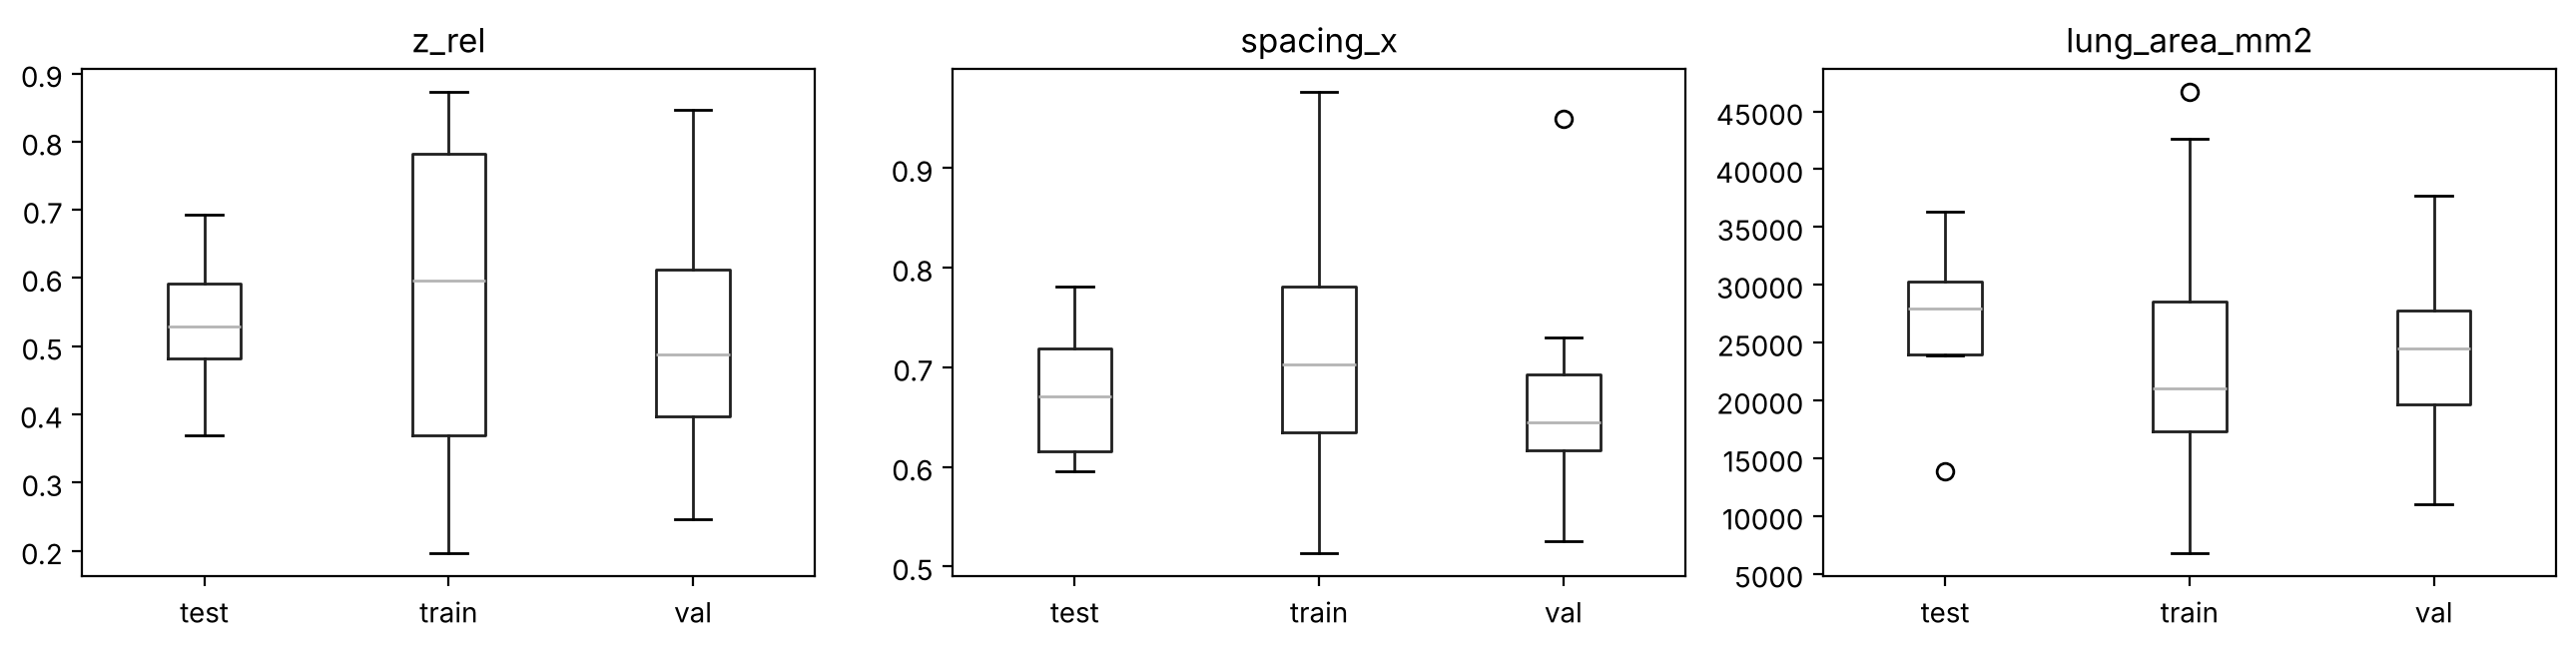

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["z_rel", "spacing_x", "lung_area_mm2"]):
    meta.boxplot(column=col, by="split", ax=ax, grid=False)
    ax.set_title(col); ax.set_xlabel("")
plt.suptitle(""); plt.tight_layout(); plt.show()

> 🧠 **Question:** the folds look similar here. Name two situations in which a clinically relevant distribution shift between train and the data the model will meet later would *not* show up in this table.

**Answer.** Anything not in the metadata: a different scanner vendor / reconstruction kernel (noise texture, HU calibration),
a different hospital or population (children, severe fibrosis, large pleural effusions, pneumothorax, post-surgical lungs),
a contrast-enhanced vs non-contrast protocol, slices outside the LUNA16 range. LUNA16 itself comes from the public LIDC-IDRI
collection (US, mostly screening-type CT), so "works on LUNA16" is not "works in our hospital". We revisit this on day 3 (robustness).

## Part 2 - The data pipeline, recap (about 25 min)

From notebook 02. These are **the** course transforms: every notebook and the web app use exactly this pre-processing,
otherwise a model trained here would see different images in production (*training-serving skew*, day 4).

* clip the HU window to `[-1000, 400]` and rescale to `[0, 1]`;
* resize **image and label** to `IMG_SIZE x IMG_SIZE` (`bilinear` for the image, `nearest` for the label: never invent label values like 0.5);
* merge right and left lung into one class (trachea counts as background);
* for training only: small random rotations/scales/shifts and a bit of noise (*augmentation*).

In [14]:
def lungs_only(x):
    """1 = right lung, 2 = left lung -> 1; everything else (incl. trachea) -> 0."""
    return ((x == 1) | (x == 2)).to(x.dtype)


def get_transforms(img_size, hu_min=-1000, hu_max=400, augment=False):
    keys = ["image", "label"]
    t = [
        LoadImaged(keys=keys),
        EnsureChannelFirstd(keys=keys),
        Lambdad(keys="label", func=lungs_only),
        ScaleIntensityRanged(keys="image", a_min=hu_min, a_max=hu_max, b_min=0.0, b_max=1.0, clip=True),
        Resized(keys=keys, spatial_size=(img_size, img_size), mode=("bilinear", "nearest")),
    ]
    if augment:
        t += [
            RandAffined(keys=keys, prob=0.5, rotate_range=0.15, scale_range=0.1, translate_range=img_size * 0.05,
                        mode=("bilinear", "nearest"), padding_mode="zeros"),
            RandGaussianNoised(keys="image", prob=0.2, std=0.02),
        ]
    t += [EnsureTyped(keys=keys)]
    return Compose(t)

### ✏️ Exercise 2.1 - Two pipelines: train (with augmentation) and validation (without)
Create `train_tf` and `val_tf` for `IMG_SIZE`.

> ⚠️ **Pitfall:** never augment the validation set. We want to measure the model on realistic, *unmodified* images; augmentation is only a training trick to make the model see more variety.

<details>
<summary>💡 Hint 1</summary>

Look at the signature of `get_transforms`: the flag `augment` is what makes the two pipelines different.

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`get_transforms(IMG_SIZE, augment=True)` for training, `get_transforms(IMG_SIZE)` for validation.

</details>

In [15]:
train_tf = get_transforms(IMG_SIZE, augment=True)
val_tf = get_transforms(IMG_SIZE)

nvImageCodec is not available; skipping pydicom decoder plugin registration.


/usr/local/lib/python3.13/site-packages/monai/data/image_reader.py:1166: UserWarning: NvImgCodecPydicomReader: nvImageCodec decoder plugin did not register successfully. Falling back to default pydicom decoders.
  warnings.warn(
nvImageCodec is not available; skipping pydicom decoder plugin registration.


In [16]:
# Check 2.1
assert len(train_tf.transforms) > len(val_tf.transforms), "the train pipeline must contain the random transforms"
sample = val_tf(val_files[0])
assert tuple(sample["image"].shape) == (1, IMG_SIZE, IMG_SIZE), sample["image"].shape
assert 0.0 <= float(sample["image"].min()) and float(sample["image"].max()) <= 1.0
assert set(np.unique(sample["label"].numpy())) <= {0.0, 1.0}, "binary lung mask expected"
print("✅ Exercise 2.1 passed")

✅ Exercise 2.1 passed


### Dataset and DataLoader
* `CacheDataset` runs the **deterministic** transforms (loading, windowing, resizing) once and keeps the results in RAM, so epochs
  are fast. The **random** transforms (`RandAffined`, noise) are still applied on the fly at every access, so *each epoch sees a
  different augmentation* of the same cached slice. (MONAI knows which transforms are random and only caches the ones before them.)
* `DataLoader` groups samples into **batches** (tensors of shape `[B, 1, H, W]`) and optionally shuffles them.

In [17]:
train_ds = CacheDataset(train_files, transform=train_tf, cache_rate=1.0, num_workers=NUM_WORKERS)
val_ds = CacheDataset(val_files, transform=val_tf, cache_rate=1.0, num_workers=NUM_WORKERS)
print(len(train_ds), len(val_ds))

Loading dataset:   0%|          | 0/63 [00:00<?, ?it/s]

Loading dataset:  21%|██        | 13/63 [00:00<00:00, 128.47it/s]

Loading dataset:  49%|████▉     | 31/63 [00:00<00:00, 149.86it/s]

Loading dataset:  78%|███████▊  | 49/63 [00:00<00:00, 162.75it/s]

Loading dataset: 100%|██████████| 63/63 [00:00<00:00, 158.91it/s]

Loading dataset:   0%|          | 0/18 [00:00<?, ?it/s]

Loading dataset:  94%|█████████▍| 17/18 [00:00<00:00, 164.13it/s]

Loading dataset: 100%|██████████| 18/18 [00:00<00:00, 167.97it/s]

63 18


### ✏️ Exercise 2.2 - The two DataLoaders
Fill in `batch_size` (use `BATCH_SIZE`) and `shuffle`.

> 🧠 **Question:** Why do we shuffle the training loader but **not** the validation loader?

<details>
<summary>💡 Hint 1</summary>

Shuffling matters when the order of the data could bias the gradient steps (training). For evaluation, the order cannot change the result.

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`shuffle=True` for `train_loader`, `shuffle=False` for `val_loader`.

</details>

In [18]:
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

In [19]:
# Check 2.2
batch = next(iter(train_loader))
assert batch["image"].shape[1:] == (1, IMG_SIZE, IMG_SIZE), batch["image"].shape
assert batch["image"].shape[0] == min(BATCH_SIZE, len(train_ds))
assert isinstance(train_loader.sampler, torch.utils.data.RandomSampler), "the training loader must shuffle"
assert not isinstance(val_loader.sampler, torch.utils.data.RandomSampler), "the validation loader must not shuffle"
print("✅ Exercise 2.2 passed")

✅ Exercise 2.2 passed


**Answer 2.2.** Shuffling gives a different mixture of cases in each mini-batch every epoch, which decorrelates consecutive gradient steps and
helps the optimiser. In validation we only *measure*: the mean over all cases is the same in any order, and a fixed order lets us
match predictions with `case_id`s afterwards (we do that in part 8).

### Always look at a batch before training
Half of all deep-learning bugs are data bugs (wrong orientation, mask not aligned, empty masks, wrong intensity range).

image: (16, 1, 256, 256) torch.float32 range [-0.08, 1.04]
label: (16, 1, 256, 256) values [0.0, 1.0]


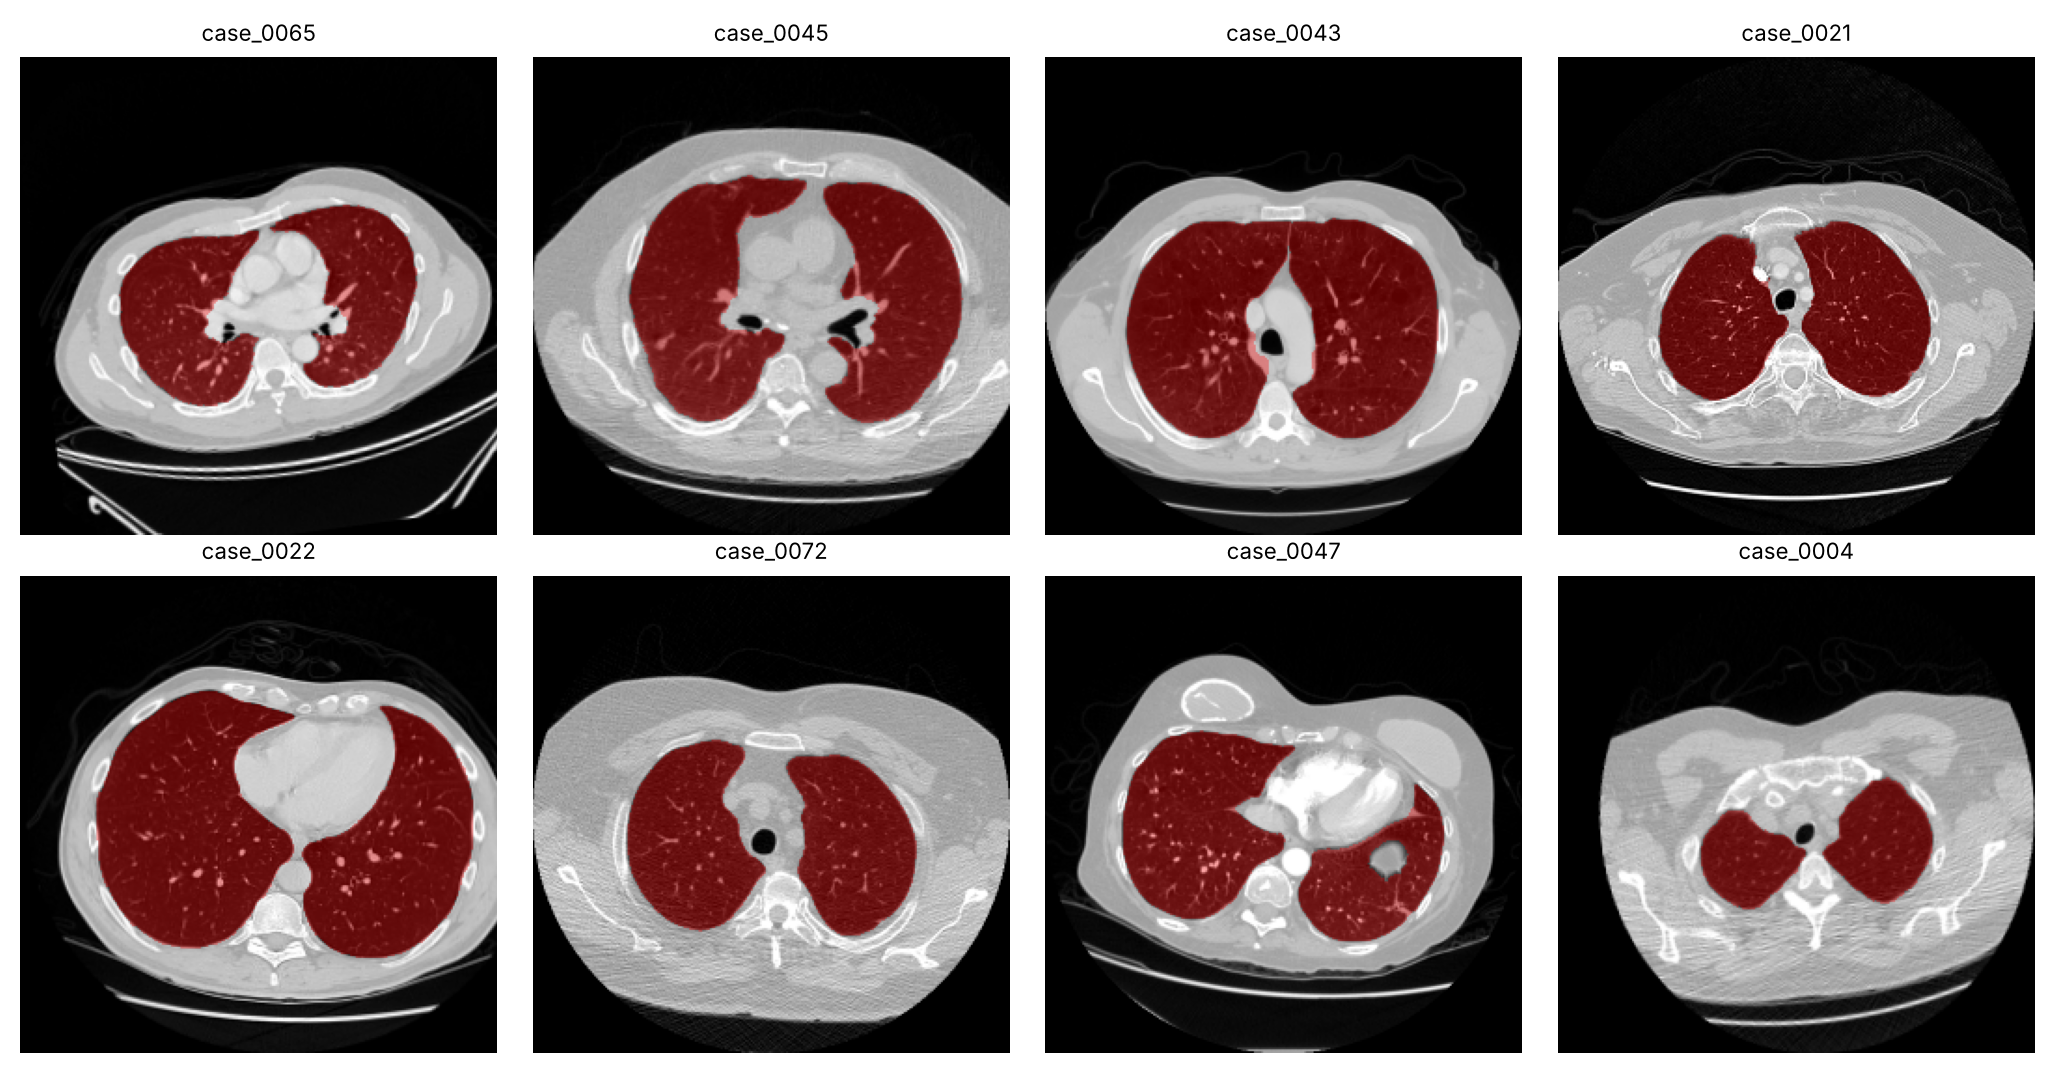

In [20]:
OVERLAY = ListedColormap(["red"])


def show_overlay(ax, img, mask, title="", alpha=0.35):
    """img, mask: 2D arrays in the dataset's (x, y) order. `.T` gives the radiological view."""
    ax.imshow(img.T, cmap="gray", vmin=0, vmax=1)
    ax.imshow(np.ma.masked_where(mask.T == 0, mask.T), cmap=OVERLAY, alpha=alpha, vmin=0, vmax=1)
    ax.set_title(title, fontsize=8); ax.axis("off")


def show_batch(batch, n=8):
    n = min(n, batch["image"].shape[0])
    fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(2.6 * ((n + 1) // 2), 5.4))
    for ax, i in zip(axes.ravel(), range(n)):
        show_overlay(ax, batch["image"][i, 0].numpy(), batch["label"][i, 0].numpy(), batch["case_id"][i])
    plt.tight_layout(); plt.show()


batch = next(iter(train_loader))
print("image:", tuple(batch["image"].shape), batch["image"].dtype, f"range [{batch['image'].min():.2f}, {batch['image'].max():.2f}]")
print("label:", tuple(batch["label"].shape), "values", batch["label"].unique().tolist())
show_batch(batch)

> 🔍 **Explore**
> * Re-run the cell above a few times: the *same* patients (cached) look slightly different each time. That is augmentation at work.
> * Does every mask sit exactly on the lungs? (Remember: the labels are produced by an algorithm, a "silver standard".)
> * Is the label of an augmented image still aligned with the image? Why is it important that `RandAffined` has `keys=["image", "label"]`?

## Part 3 - The model: a U-Net (about 30 min)

**The U-Net idea in six lines.**
1. The **encoder** repeatedly halves the resolution and doubles the number of feature maps: it learns *what* is in the image (context).
2. At the **bottleneck** the image is tiny (16 x 16) but every pixel "sees" a large part of the chest.
3. The **decoder** upsamples back to the original resolution: it recovers *where* things are.
4. **Skip connections** copy the high-resolution feature maps from the encoder to the decoder at the same level, so that sharp
   lung borders are not lost in the down-sampling.
5. The last layer is a 1x1 convolution that turns the features into **one score per class per pixel** (logits).
6. The output has the same height and width as the input: a prediction for **every pixel**.

```
 input 1 x 256 x 256
 +--------------------+                                   +--------------------+
 | enc1  16 ch  256^2 |--------- skip connection -------->| dec1  16 ch  256^2 |--> 1x1 conv --> 2 x 256 x 256 (logits)
 +--------------------+                                   +--------------------+
           | stride 2                                                ^ upsample x2
 +--------------------+                                   +--------------------+
 | enc2  32 ch  128^2 |--------- skip connection -------->| dec2  32 ch  128^2 |
 +--------------------+                                   +--------------------+
           | stride 2                                                ^
 +--------------------+                                   +--------------------+
 | enc3  64 ch   64^2 |--------- skip connection -------->| dec3  64 ch   64^2 |
 +--------------------+                                   +--------------------+
           | stride 2                                                ^
 +--------------------+                                   +--------------------+
 | enc4 128 ch   32^2 |--------- skip connection -------->| dec4 128 ch   32^2 |
 +--------------------+                                   +--------------------+
           | stride 2                                                ^
           +-----------------> bottleneck 256 ch 16^2 --------------+
```

### MONAI `UNet` arguments, one by one

| argument | meaning | our value |
|---|---|---|
| `spatial_dims` | 2 for images, 3 for volumes | 2 |
| `in_channels` | channels of the input: a CT slice is grey-scale | 1 |
| `out_channels` | number of classes = number of logit maps | 2 (background, lung) |
| `channels` | feature maps at each level; one more entry than `strides` | `[16, 32, 64, 128, 256]` |
| `strides` | down-sampling factor between consecutive levels | `[2, 2, 2, 2]` |
| `num_res_units` | residual units per level (a skip *inside* a block; helps optimisation) | 2 |

**Why 2 output channels and not 1?** With a single channel we would use a sigmoid and a threshold (also perfectly valid, and the
common choice for binary tasks). We use 2 channels + softmax + argmax because it is the *same code* that works for 3, 4 or more
classes (day 4 side tasks) and because it is what the MONAI tutorials do. The model outputs raw **logits**: no softmax inside the network.

> 📚 **Read more:** U-Net paper https://arxiv.org/abs/1505.04597 · MONAI networks https://docs.monai.io/en/stable/networks.html

### ✏️ Exercise 3.1 - Build the U-Net
Fill in the architecture arguments (use **lists** for `channels` and `strides`, they will go into a JSON file later).

<details>
<summary>💡 Hint 1</summary>

The table above gives every value. Remember `len(channels) == len(strides) + 1`.

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`spatial_dims=2, in_channels=1, out_channels=2, channels=[16, 32, 64, 128, 256], strides=[2, 2, 2, 2]`

</details>

In [21]:
arch_kwargs = dict(spatial_dims=2, in_channels=1, out_channels=2,
                   channels=[16, 32, 64, 128, 256], strides=[2, 2, 2, 2], num_res_units=2)
model = UNet(**arch_kwargs).to(device)


def new_model():
    """A freshly initialised U-Net with our architecture, on the right device."""
    return UNet(**arch_kwargs).to(device)


n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable parameters: {n_params:,}")

trainable parameters: 1,625,161


In [22]:
# Check 3.1
assert arch_kwargs["spatial_dims"] == 2 and arch_kwargs["in_channels"] == 1 and arch_kwargs["out_channels"] == 2
assert len(arch_kwargs["channels"]) == len(arch_kwargs["strides"]) + 1
assert isinstance(model, UNet)
print("✅ Exercise 3.1 passed")

✅ Exercise 3.1 passed


### ✏️ Exercise 3.2 - Forward a dummy batch and read the output shape
Create a random batch of 4 single-channel images of size `IMG_SIZE x IMG_SIZE`, run it through the model
(without computing gradients: we only want to look) and print the shape of the output.
**Before running**, predict the shape. Then check.

<details>
<summary>💡 Hint 1</summary>

Input shape convention in PyTorch: `[batch, channels, height, width]`. A CT slice has 1 channel.

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`dummy = torch.randn(4, 1, IMG_SIZE, IMG_SIZE, device=device)` and `with torch.no_grad(): out = model(dummy)`

</details>

In [23]:
dummy = torch.randn(4, 1, IMG_SIZE, IMG_SIZE, device=device)
with torch.no_grad():
    out = model(dummy)
print("input :", tuple(dummy.shape))
print("output:", tuple(out.shape))

input : (4, 1, 256, 256)
output: (4, 2, 256, 256)


In [24]:
# Check 3.2
assert tuple(out.shape) == (4, 2, IMG_SIZE, IMG_SIZE), f"unexpected output shape {tuple(out.shape)}"
assert not out.requires_grad, "use torch.no_grad() when you only want to look at the output"
print("✅ Exercise 3.2 passed: 2 logit maps (background, lung) for every pixel of every image")

✅ Exercise 3.2 passed: 2 logit maps (background, lung) for every pixel of every image


### ⚠️ The input size must be divisible by 2^(number of strides)
We down-sample 4 times by 2, so height and width must be divisible by 2^4 = **16**. Otherwise the decoder's upsampled map does not
have the same size as the skip connection it has to be concatenated with.

> 🔍 **Explore:** run the cell below. Then try other sizes: 256, 272, 255, 300, 512. Which ones work? Why is `250` a problem but `272` is fine?

In [25]:
size = 250   # try also: 256, 272, 255, 300, 512
try:
    with torch.no_grad():
        print(tuple(model(torch.randn(1, 1, size, size, device=device)).shape), "-> works")
except RuntimeError as err:
    print(f"{size}x{size} fails ({size} % 16 = {size % 16}):\n  {str(err)[:120]}")

250x250 fails (250 % 16 = 10):
  Sizes of tensors must match except in dimension 1. Expected size 63 but got size 64 for tensor number 1 in the list.


### Receptive field: how much context does a pixel see?
Each 3x3 convolution looks 1 pixel around; each stride-2 step doubles how far the next convolutions reach in the original image.
The helper below follows the encoder (an approximation: it ignores the decoder and the residual branches).

In [26]:
def encoder_receptive_field(n_levels=4, convs_per_level=2, kernel=3):
    """Receptive field (in input pixels) of the deepest encoder feature, for stride 2 between levels."""
    rf, jump = 1, 1
    for level in range(n_levels + 1):
        for conv in range(convs_per_level):
            stride = 2 if (level > 0 and conv == 0) else 1
            rf += (kernel - 1) * jump
            jump *= stride
    return rf

rf = encoder_receptive_field(len(arch_kwargs["strides"]))
print(f"deepest encoder feature sees about {rf} x {rf} input pixels "
      f"= {rf / IMG_SIZE:.0%} of the image width at IMG_SIZE={IMG_SIZE}, {rf / 256:.0%} at 256, {rf / 512:.0%} at 512")

deepest encoder feature sees about 95 x 95 input pixels = 37% of the image width at IMG_SIZE=256, 37% at 256, 19% at 512


> 🧠 **Question:** (a) Why is a large receptive field useful for finding lungs? (b) If we ran the same network on the full 512 x 512 slices instead of the 256 x 256 ones, what would change for the receptive field, and what would it cost?

**Answer.** (a) A pixel alone cannot tell "lung" from "air in the bowel" or "air outside the body": a dark pixel inside the thorax, next to the
mediastinum and surrounded by ribs is lung. Context (position relative to body outline, spine, heart) resolves the ambiguity; a pure
local threshold cannot (day 1 baseline!). (b) The receptive field is fixed in *pixels*, so at 512 it covers only half as much anatomy; the network
would see less context per prediction. The cost: 4x the pixels -> about 4x memory and compute per image, so smaller batches. For lung
masks 256 is a good trade-off; for small structures (nodules, vessels) one would need the full resolution.

## Part 4 - Loss and metric (about 35 min)

### The class-imbalance problem
Let us measure how much of an image is lung.

In [27]:
y = batch["label"]
fg_fraction = (y > 0).float().mean().item()
print(f"foreground (lung) fraction of the pixels in this batch: {fg_fraction:.1%}")
print(f"accuracy of a model that predicts 'background' everywhere: {1 - fg_fraction:.1%}")

foreground (lung) fraction of the pixels in this batch: 18.3%
accuracy of a model that predicts 'background' everywhere: 81.7%


A useless model that never predicts any lung would already be "right" for most pixels. **Accuracy** (and plain cross-entropy,
which averages over pixels) rewards that. On a mid-chest slice the lungs are roughly a fifth of the pixels, but for small structures
(a nodule, a tumour, a vessel) the foreground can be well below 1%, and the problem becomes dramatic.

**Dice** measures the *overlap* between prediction $P$ and ground truth $G$ and ignores the true-negative background:

$$\mathrm{Dice}(P, G) = \frac{2\,|P \cap G|}{|P| + |G|} \in [0, 1]$$

1 = perfect overlap, 0 = no overlap. The all-background model has Dice **0** although its accuracy is high.

### Loss vs metric: soft vs hard
* A **loss** must be *differentiable*: we need a gradient to update the weights. So the **soft Dice loss** uses the predicted
  *probabilities* (softmax output between 0 and 1) instead of hard 0/1 decisions: `1 - Dice(probabilities, mask)`.
* A **metric** reports performance in the real world: we take the hard decision (`argmax`), then compute Dice on binary masks. No gradient needed.

### ✏️ Exercise 4.1 - Soft Dice loss, by hand
Implement the soft Dice loss for the **foreground channel** on tensors. `logits` has shape `[B, 2, H, W]`, `target` has shape `[B, 1, H, W]` with 0/1.
The Dice is computed **per image** (sum over H and W), then averaged over the batch.

<details>
<summary>💡 Hint 1</summary>

First turn logits into probabilities with softmax over the **channel** dimension (dim 1), then keep channel 1 (the lung).

</details>

<details>
<summary>💡 Hint 2</summary>

Intersection = `(probs * t).sum(dim=(1, 2))`; denominator = `probs.sum(dim=(1, 2)) + t.sum(dim=(1, 2))`.

</details>

<details>
<summary>💡 Hint 3 (almost the solution)</summary>

`dice = 2 * inter / (denom + eps)` and the loss is `1 - dice.mean()`.

</details>

In [28]:
def soft_dice_loss(logits, target, eps=1e-5):
    """1 - soft Dice of the foreground class, averaged over the batch."""
    probs = torch.softmax(logits, dim=1)[:, 1]        # [B, H, W] probability of "lung"
    t = target[:, 0].float()                          # [B, H, W] 0/1 mask
    inter = (probs * t).sum(dim=(1, 2))
    denom = probs.sum(dim=(1, 2)) + t.sum(dim=(1, 2))
    dice = 2 * inter / (denom + eps)
    return 1 - dice.mean()

In [29]:
# Check 4.1: compare with MONAI's implementation on random data
g = torch.Generator().manual_seed(0)
lg = torch.randn(4, 2, 32, 32, generator=g)
tg = (torch.rand(4, 1, 32, 32, generator=g) > 0.7).float()
monai_dice = DiceLoss(include_background=False, to_onehot_y=True, softmax=True)
mine, ref = soft_dice_loss(lg, tg).item(), monai_dice(lg, tg).item()
print(f"mine {mine:.5f} | MONAI {ref:.5f}")
assert abs(mine - ref) < 1e-4, "your loss differs from monai.losses.DiceLoss(include_background=False, ...)"
perfect = torch.cat([1 - tg, tg], dim=1) * 20 - 10          # confident, correct logits
assert soft_dice_loss(perfect, tg).item() < 0.01, "a perfect prediction must give a loss close to 0"
assert soft_dice_loss(-perfect, tg).item() > 0.95, "a completely wrong prediction must give a loss close to 1"
print("✅ Exercise 4.1 passed")

mine 0.61535 | MONAI 0.61535
✅ Exercise 4.1 passed


### Cross-entropy, Dice, and DiceCE
* **Cross-entropy (CE)** is a per-pixel classification loss: smooth gradients, stable at the beginning of training, but dominated by the
  background when the foreground is small.
* **Dice loss** looks at the overlap directly and is robust to imbalance, but its gradients can be noisy/unstable when the overlap is
  small (early training) or the mask is empty.
* **`DiceCELoss`** = Dice loss + CE: it gets the best of both and is the robust default in MONAI. This is what we use.

Let us compare them on a **lazy** model that gives every pixel the same probability, namely the foreground fraction:

In [30]:
x_b, y_b = batch["image"].to(device), batch["label"].to(device)
p = fg_fraction
lazy_logits = torch.zeros(x_b.shape[0], 2, IMG_SIZE, IMG_SIZE, device=device)
lazy_logits[:, 1] = float(np.log(p / (1 - p)))          # softmax -> P(lung) = p everywhere

ce = F.cross_entropy(lazy_logits, y_b[:, 0].long())     # CE wants class indices [B, H, W]
dice_l = DiceLoss(to_onehot_y=True, softmax=True, include_background=False)(lazy_logits, y_b)
dice_ce = DiceCELoss(to_onehot_y=True, softmax=True)(lazy_logits, y_b)
print(f"lazy model -> CE {ce.item():.3f} | Dice loss {dice_l.item():.3f} | DiceCE {dice_ce.item():.3f}")

# DiceCELoss really is "Dice + CE" (its Dice includes the background channel by default):
both = DiceLoss(to_onehot_y=True, softmax=True)(lazy_logits, y_b) + ce
assert torch.allclose(both, dice_ce, atol=1e-5)
print("DiceCELoss == DiceLoss + CrossEntropy:", torch.allclose(both, dice_ce, atol=1e-5))

lazy model -> CE 0.475 | Dice loss 0.827 | DiceCE 0.981
DiceCELoss == DiceLoss + CrossEntropy: True


> 🧠 **Question:** the lazy model has a CE of about 0.5, which does not look terrible, but its Dice loss is about 0.8. What does each loss tell us about this model? Why do we want both signals?

**Answer.** CE says "on average the probabilities are not too far from the truth" because most pixels are background and are predicted OK
(the entropy of a 20/80 split is low). Dice says "you have found none of the structure we care about": the model has zero information about *where* the lungs are,
so the overlap is at chance level. CE gives smooth, well-behaved gradients that get the network started; Dice pushes
directly on the quantity we care about and compensates for imbalance. Together: stable *and* aligned with the final metric.

### The metric: `DiceMetric`, `AsDiscrete` and `decollate_batch`
For evaluation we need **hard** masks. This is the idiom used in every MONAI tutorial, and the place where students most often get lost:

```
model output  [B, 2, H, W]  (a batch tensor of logits)
     |  decollate_batch               -> a LIST of B tensors, each [2, H, W]
     |  post_pred (per item):  AsDiscrete(argmax=True, to_onehot=2)
     |                         argmax over the class channel, then one-hot: [2, H, W] with exact 0/1
     v
list of hard predictions  ---+
                             +--> DiceMetric(y_pred=list, y=list)  -> Dice per case
list of hard labels  --------+
     ^  post_label (per item): AsDiscrete(to_onehot=2)   ([1, H, W] label -> [2, H, W] one-hot)
     |  decollate_batch
label  [B, 1, H, W]
```

* **Why a list?** MONAI's post-processing transforms are written for **one sample**, channel-first. `AsDiscrete(argmax=True)`
  takes the argmax over dimension 0, the channel dimension of a single sample. `decollate_batch` splits the batch into those single samples.
* **`DiceMetric(include_background=False)`**: the Dice of the *background* channel is always very high and would inflate the score. We only want the lung Dice.
* The metric **accumulates** per-case values every time you call it; `aggregate()` averages them, `reset()` clears the buffer for the next evaluation.

In [31]:
post_pred = AsDiscrete(argmax=True, to_onehot=2)
post_label = AsDiscrete(to_onehot=2)
dice_metric = DiceMetric(include_background=False, reduction="mean")

> ⚠️ **Pitfall:** applying `post_pred` to the whole batch instead of single samples. The `argmax` would run over the *batch* dimension.
> With a batch of 4 images you get a loud error, with a batch of exactly 2 images a silently wrong result. Look:

In [32]:
with torch.no_grad():
    logits_demo = model(x_b)
print("batch of logits:", tuple(logits_demo.shape))
try:
    post_pred(logits_demo)
except RuntimeError as err:
    print("  post_pred(batch) -> RuntimeError:", str(err)[:70])
items = decollate_batch(logits_demo)
print("decollate_batch ->", type(items).__name__, "of", len(items), "tensors, each", tuple(items[0].shape))
print("post_pred(one item) ->", tuple(post_pred(items[0]).shape), "values", post_pred(items[0]).unique().tolist())

batch of logits: (16, 2, 256, 256)
  post_pred(batch) -> RuntimeError: index 9 is out of bounds for dimension 0 with size 2
decollate_batch -> list of 16 tensors, each (2, 256, 256)
post_pred(one item) -> (2, 256, 256) values [0.0, 1.0]


### ✏️ Exercise 4.2 - The Dice of an untrained model
Take **one validation batch**, run the (untrained!) model, and compute the mean Dice with `dice_metric`. Expect something bad: the network is still random.

<details>
<summary>💡 Hint 1</summary>

Both the logits and the labels must be turned into lists of single samples with `decollate_batch` before the post-transforms.

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`preds = [post_pred(p) for p in decollate_batch(logits)]` and the same with `post_label` for `y`.
Then `dice_metric(y_pred=preds, y=labels)`, `dice_metric.aggregate().item()`, and don't forget `dice_metric.reset()`.

</details>

In [33]:
val_batch = next(iter(val_loader))
xv, yv = val_batch["image"].to(device), val_batch["label"].to(device)
model.eval()
with torch.no_grad():
    logits = model(xv)
preds = [post_pred(p) for p in decollate_batch(logits)]
labels = [post_label(l) for l in decollate_batch(yv)]
dice_metric(y_pred=preds, y=labels)
untrained_dice = dice_metric.aggregate().item()
dice_metric.reset()
print(f"Dice of the untrained model on one validation batch: {untrained_dice:.3f}")

Dice of the untrained model on one validation batch: 0.255


In [34]:
# Check 4.2
assert isinstance(preds, list) and len(preds) == xv.shape[0] and tuple(preds[0].shape) == (2, IMG_SIZE, IMG_SIZE)
assert 0.0 <= untrained_dice <= 1.0
print("✅ Exercise 4.2 passed (a random network has no idea where the lungs are, so the number is poor)")

✅ Exercise 4.2 passed (a random network has no idea where the lungs are, so the number is poor)


> 🔍 **Explore**
> * Write `lazy_pred = torch.zeros_like(yv)` (all background) and compute its Dice. What does `DiceMetric` return when a prediction is empty?
> * Shift the ground truth by 3 pixels with `torch.roll(yv, shifts=3, dims=-1)` and compute the Dice between the mask and its shifted copy. How sensitive is Dice to a small misalignment on a large organ?
> * Compute the Dice per case (`reduction="none"`): is the mean a good summary, or can one terrible case hide in it? (We do this for real in part 8.)

## Part 5 - Sanity checks before training (about 20 min)

A training run that takes an hour and fails silently is expensive. Experienced practitioners always run **two cheap checks first**
([A. Karpathy, "A Recipe for Training Neural Networks"](https://karpathy.github.io/2019/04/25/recipe/)):

1. **Is the loss at initialisation plausible?** With 2 classes and a network that is almost uniform, the cross-entropy should be about $\ln 2 \approx 0.69$.
   A very different value (50.0, or 0.0) points to a bug (wrong target shape, missing softmax, wrong labels...).
2. **Can the model overfit a single batch?** Take 4 images, train on only those for a few dozen steps: the loss must go to (almost) 0 and the
   prediction must match the masks. If a network cannot even memorise 4 images, there is a bug in the loss, the data, or the training step:
   don't waste a long run.

In [35]:
loss_fn = DiceCELoss(to_onehot_y=True, softmax=True)   # Dice + cross-entropy, the robust default
fresh = new_model().eval()
with torch.no_grad():
    init_logits = fresh(xv)
print(f"CE at initialisation  : {F.cross_entropy(init_logits, yv[:, 0].long()).item():.3f} (uniform guess = ln 2 = {np.log(2):.3f})")
print(f"DiceCE at initialisation: {loss_fn(init_logits, yv).item():.3f}")

CE at initialisation  : 0.846 (uniform guess = ln 2 = 0.693)
DiceCE at initialisation: 1.401


### The 5 lines of every PyTorch training step
1. `optimizer.zero_grad()` - clear the gradients of the previous step (PyTorch *accumulates* them otherwise);
2. `logits = model(x)` - forward pass;
3. `loss = loss_fn(logits, y)` - how wrong are we?
4. `loss.backward()` - back-propagation: compute the gradient of the loss with respect to every weight;
5. `optimizer.step()` - update the weights (Adam, learning rate `lr`).

### ✏️ Exercise 5.1 - Overfit one batch
Complete the training step inside `overfit_one_batch`. The function trains a **fresh** model on 4 fixed images and returns the loss at every step
and the trained model.

<details>
<summary>💡 Hint 1</summary>

The order matters: reset gradients, forward, loss, backward, update. Use the names `logits` and `loss` (the last line of the loop uses `loss`).

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`optimizer.zero_grad()`, `logits = net(x0)`, `loss = loss_fn(logits, y0)`, `loss.backward()`, `optimizer.step()`

</details>

In [36]:
x0, y0 = xv[:4].detach().clone(), yv[:4].detach().clone()   # the single batch we try to memorise
OVERFIT_STEPS = 15 if FAST else 50


def overfit_one_batch(lr, steps=OVERFIT_STEPS, seed=0):
    torch.manual_seed(seed)
    net = new_model().train()
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)
    losses = []
    for step in range(steps):
        optimizer.zero_grad()
        logits = net(x0)
        loss = loss_fn(logits, y0)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    return losses, net


t0 = time.perf_counter()
overfit_losses, overfit_net = overfit_one_batch(LR)
print(f"{OVERFIT_STEPS} steps in {time.perf_counter() - t0:.1f}s | loss {overfit_losses[0]:.3f} -> {overfit_losses[-1]:.3f}")

50 steps in 10.8s | loss 1.283 -> 0.434


In [37]:
# Check 5.1
assert len(overfit_losses) == OVERFIT_STEPS
assert overfit_losses[-1] < overfit_losses[0], "the loss did not decrease: check the 5 lines (is every one of them there, in the right order?)"
if not FAST:
    assert overfit_losses[-1] < 0.5 * overfit_losses[0], "the loss should at least halve in ~50 steps on a single batch"
print("✅ Exercise 5.1 passed")

✅ Exercise 5.1 passed


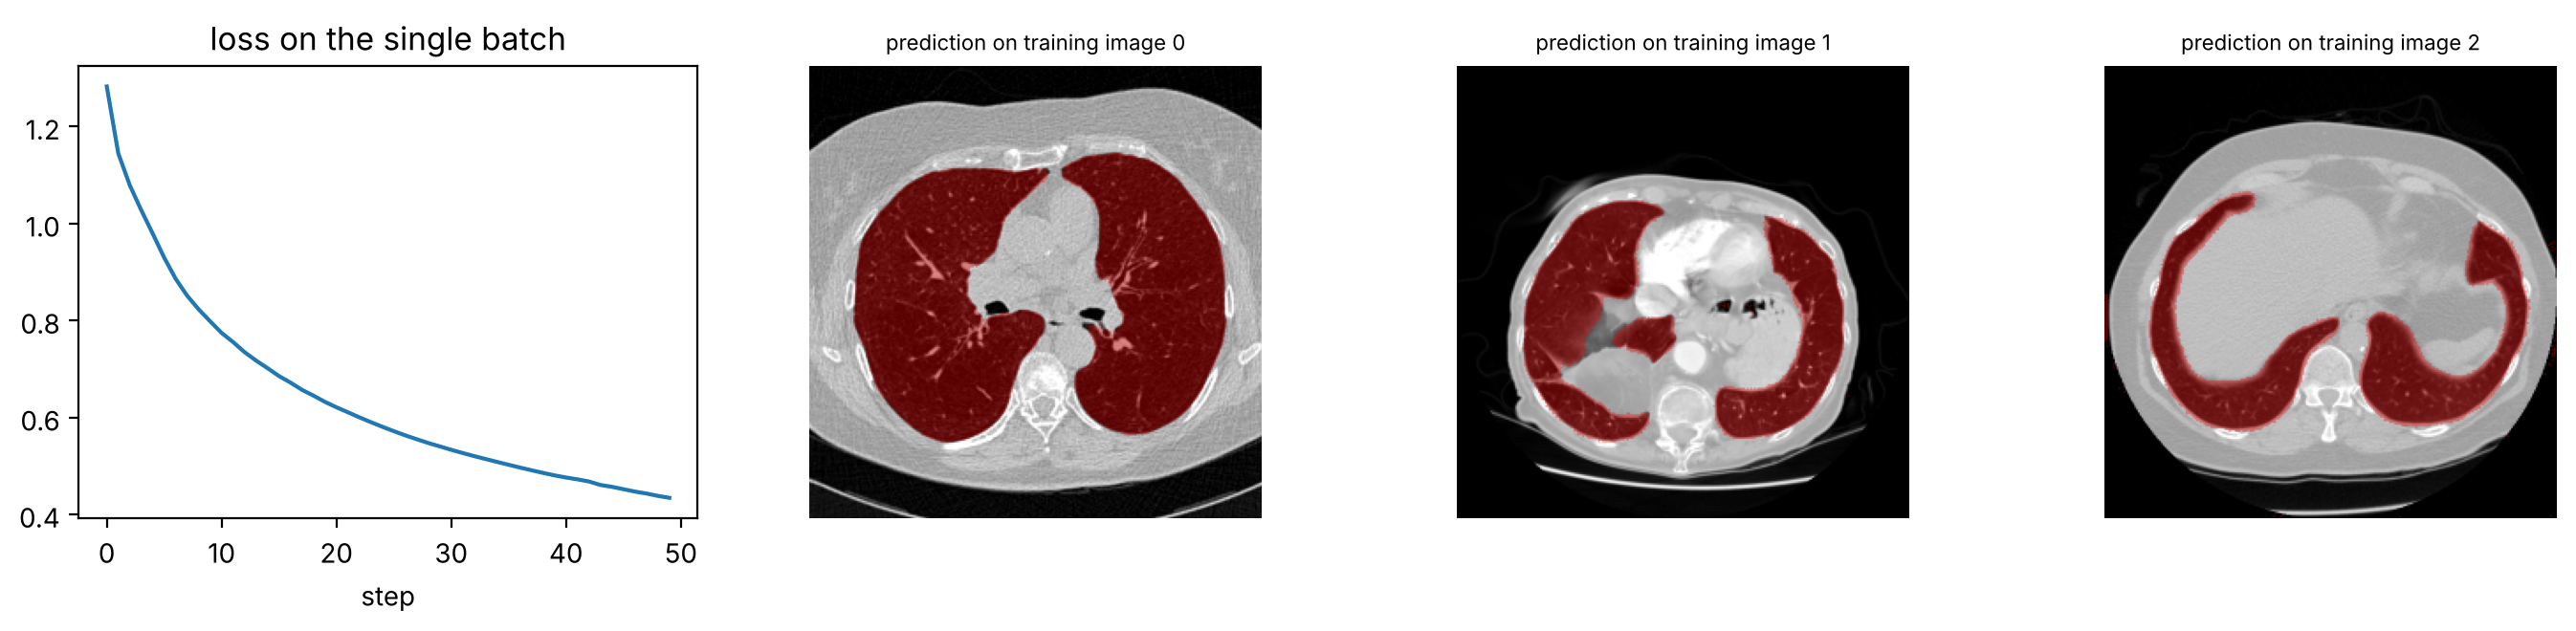

In [38]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
axes[0].plot(overfit_losses); axes[0].set_title("loss on the single batch"); axes[0].set_xlabel("step")
overfit_net.eval()
with torch.no_grad():
    pred0 = overfit_net(x0).argmax(dim=1)
for k, ax in enumerate(axes[1:]):
    show_overlay(ax, x0[k, 0].cpu().numpy(), pred0[k].cpu().numpy(), f"prediction on training image {k}")
plt.tight_layout(); plt.show()

> 🧠 **Question:** the loss goes down and the prediction matches the mask on these 4 images. Does this prove that the model is *good*? What exactly did we prove?

**Answer.** No: we only proved that the pipeline is *capable of learning*: data, labels, loss and optimiser are wired correctly, and the
network has enough capacity to memorise. It says nothing about generalisation to new patients, that is what the validation set is for.
It is a necessary, not a sufficient, condition: a model that fails this test is certainly broken.

### 🔍 Explore - the learning rate
The learning rate is the most important hyper-parameter. The cell runs the same overfit test with four learning rates (it is cheap, run it!).
* Which learning rate diverges or is erratic? Which one is too slow in this budget?
* Why is `1e-3` (a power of ten near it) a good starting point for Adam, and why can't we use the same value for plain SGD?

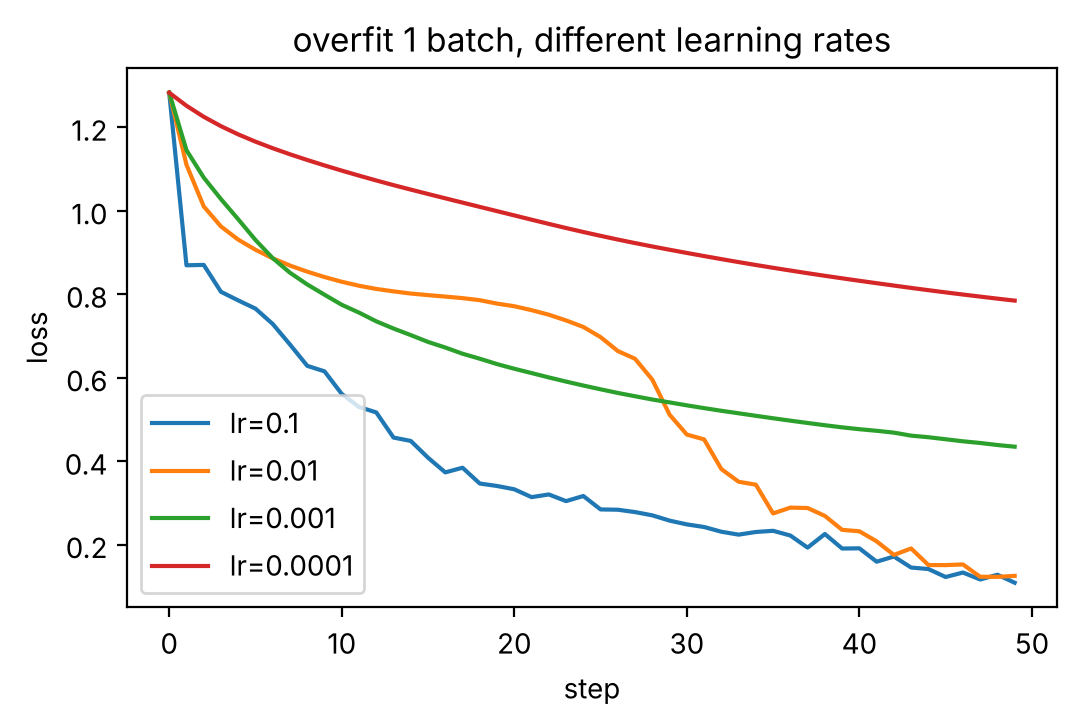

In [39]:
plt.figure(figsize=(6, 3.5))
for lr in [1e-1, 1e-2, 1e-3, 1e-4]:
    plt.plot(overfit_one_batch(lr)[0], label=f"lr={lr:g}")
plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.title("overfit 1 batch, different learning rates")
plt.show()

## Part 6 - The training loop (about 30 min + training time)

We now wrap the 5-line step into two functions we can reuse: one epoch of training, and one pass of validation.

### ✏️ Exercise 6.1 - `train_one_epoch`
Return the mean training loss over the epoch. Remember: `model.train()` switches layers like dropout/batch-norm to training behaviour
(the default U-Net uses instance norm, but the habit matters).

<details>
<summary>💡 Hint 1</summary>

Same 5 lines as in exercise 5.1, now inside a loop over `loader`. Move `batch["image"]` and `batch["label"]` to `device` first!

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`model.train()`; `x, y = batch["image"].to(device), batch["label"].to(device)`; then the 5 lines; accumulate `loss.item()`.

</details>

In [40]:
def train_one_epoch(model, loader, optimizer, loss_fn, device):
    model.train()
    total, n = 0.0, 0
    for batch in loader:
        x, y = batch["image"].to(device), batch["label"].to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = loss_fn(logits, y)
        loss.backward()
        optimizer.step()
        total += loss.item() * x.shape[0]      # weight by batch size (the last batch can be smaller)
        n += x.shape[0]
    return total / n

### ✏️ Exercise 6.2 - `validate`
Compute the mean Dice on a loader, with the idiom from part 4. Three things must be true: the model is in **eval mode**, **no gradients** are computed, and the metric is **reset** at the end.
(`post_pred` and `post_label` are passed as default arguments: you can ignore that for now, it only matters in the 🚀 3-class challenge.)

<details>
<summary>💡 Hint 1</summary>

`model.eval()` and a `with torch.no_grad():` block around the loop. Why no gradients? Memory and speed: we are not going to call `backward()`.

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

Inside the loop: `logits = model(x)`, then `decollate_batch` + post-transforms for the predictions and the labels, then `metric(y_pred=..., y=...)`.
After the loop: `metric.aggregate().item()` and `metric.reset()`.

</details>

In [41]:
def validate(model, loader, metric, device, post_pred=post_pred, post_label=post_label):
    model.eval()
    with torch.no_grad():
        for batch in loader:
            x, y = batch["image"].to(device), batch["label"].to(device)
            logits = model(x)
            preds = [post_pred(p) for p in decollate_batch(logits)]
            labels = [post_label(l) for l in decollate_batch(y)]
            metric(y_pred=preds, y=labels)
    dice = metric.aggregate().item()
    metric.reset()
    return dice

In [42]:
# Check 6.1 + 6.2 on a copy of the model and two batches, so that we do not waste time or touch the real model
from itertools import islice

probe, probe_batches = new_model(), list(islice(train_loader, 2))
w_before = [p.detach().clone() for p in probe.parameters()]
opt_probe = torch.optim.Adam(probe.parameters(), lr=LR)
l = train_one_epoch(probe, probe_batches, opt_probe, loss_fn, device)
assert isinstance(l, float) and np.isfinite(l) and l > 0, "train_one_epoch must return the mean loss as a Python float"
assert probe.training, "train_one_epoch must leave the model in training mode"
assert any(not torch.equal(a, b) for a, b in zip(w_before, probe.parameters())), "the weights did not change: is optimizer.step() called?"
w_mid = [p.detach().clone() for p in probe.parameters()]
d = validate(probe, probe_batches, dice_metric, device)
assert isinstance(d, float) and 0.0 <= d <= 1.0
assert not probe.training, "validate must put the model in eval mode"
assert all(torch.equal(a, b) for a, b in zip(w_mid, probe.parameters())), "validation must not change the weights"
print("✅ Exercises 6.1 and 6.2 passed")

✅ Exercises 6.1 and 6.2 passed


### The epoch loop
Each **epoch** = one pass over all training images. After each epoch we measure the validation Dice and keep the weights of the **best** epoch
(the last one is not necessarily the best: see part 7). We also record a `history` dict and the time per epoch.

### ✏️ Exercise 6.3 - Keep the best checkpoint
In the loop below, save the model weights whenever the validation Dice **improves**. `model.state_dict()` is the dictionary of all weights: that is
what `torch.save` should store (never pickle the whole model object).

<details>
<summary>💡 Hint 1</summary>

Keep `best_dice` (start at -1). If the new `val_dice` is **greater** than it, update `best_dice`, `best_epoch`, and save.

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`if val_dice > best_dice:` ... `torch.save(model.state_dict(), CKPT_PATH)`

</details>

### What to do while it trains
On a Kaggle T4 with the real 888 slices, 30 epochs take **a few minutes** (about 10-20 s per epoch; on a CPU it would be 20-50x slower).
While you wait: read the 📚 links of parts 3 and 4, re-read the 🧠 questions you skipped, think about what the curves should look like (part 7), and
**do not interrupt the kernel**. You will see one line per epoch: training loss, validation Dice, a `*` when the model improved.

In [43]:
set_determinism(seed=42)                      # same start for everybody
model = new_model()                           # a brand-new, untrained model
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
CKPT_PATH = WORK_DIR / "best_model.pt"

history = {"epoch": [], "train_loss": [], "val_dice": [], "seconds": []}
best_dice, best_epoch = -1.0, 0

print(f"training on {device} | {len(train_ds)} train / {len(val_ds)} val images | {MAX_EPOCHS} epochs")
for epoch in range(1, MAX_EPOCHS + 1):
    t0 = time.perf_counter()
    train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn, device)
    val_dice = validate(model, val_loader, dice_metric, device)
    seconds = time.perf_counter() - t0

    improved = val_dice > best_dice
    if improved:
        best_dice, best_epoch = val_dice, epoch
        torch.save(model.state_dict(), CKPT_PATH)

    for key, value in zip(history, [epoch, train_loss, val_dice, seconds]):
        history[key].append(value)
    print(f"epoch {epoch:3d}/{MAX_EPOCHS} | train loss {train_loss:.4f} | val Dice {val_dice:.4f} | {seconds:5.1f}s {'*' if improved else ''}")
print(f"best val Dice {best_dice:.4f} at epoch {best_epoch} -> {CKPT_PATH}")

training on cpu | 63 train / 18 val images | 30 epochs


epoch   1/30 | train loss 1.0806 | val Dice 0.5132 |   7.4s *


epoch   2/30 | train loss 0.9252 | val Dice 0.6217 |   6.9s *


epoch   3/30 | train loss 0.8727 | val Dice 0.7196 |   6.8s *


epoch   4/30 | train loss 0.8260 | val Dice 0.8053 |   6.9s *


epoch   5/30 | train loss 0.7786 | val Dice 0.8539 |   6.6s *


... (21 outputs left out)

epoch  27/30 | train loss 0.2746 | val Dice 0.9651 |   6.8s 


epoch  28/30 | train loss 0.2659 | val Dice 0.9656 |   6.5s 


epoch  29/30 | train loss 0.2572 | val Dice 0.9680 |   6.5s 


epoch  30/30 | train loss 0.2466 | val Dice 0.9642 |   7.0s 
best val Dice 0.9684 at epoch 26 -> /tmp/hi_real2/best_model.pt


In [44]:
# Check 6.3
assert CKPT_PATH.exists(), "no checkpoint saved"
assert len(history["val_dice"]) == MAX_EPOCHS
assert best_dice == max(history["val_dice"]) and history["val_dice"][best_epoch - 1] == best_dice
assert torch.load(CKPT_PATH, map_location="cpu", weights_only=True).keys() == model.state_dict().keys()
if not FAST:
    assert best_dice > 0.85, f"best val Dice {best_dice:.3f} is low: look at the curves in part 7 and ask a teacher"
print("✅ Exercise 6.3 passed")

✅ Exercise 6.3 passed


## Part 7 - Reading the learning curves (about 10 min)

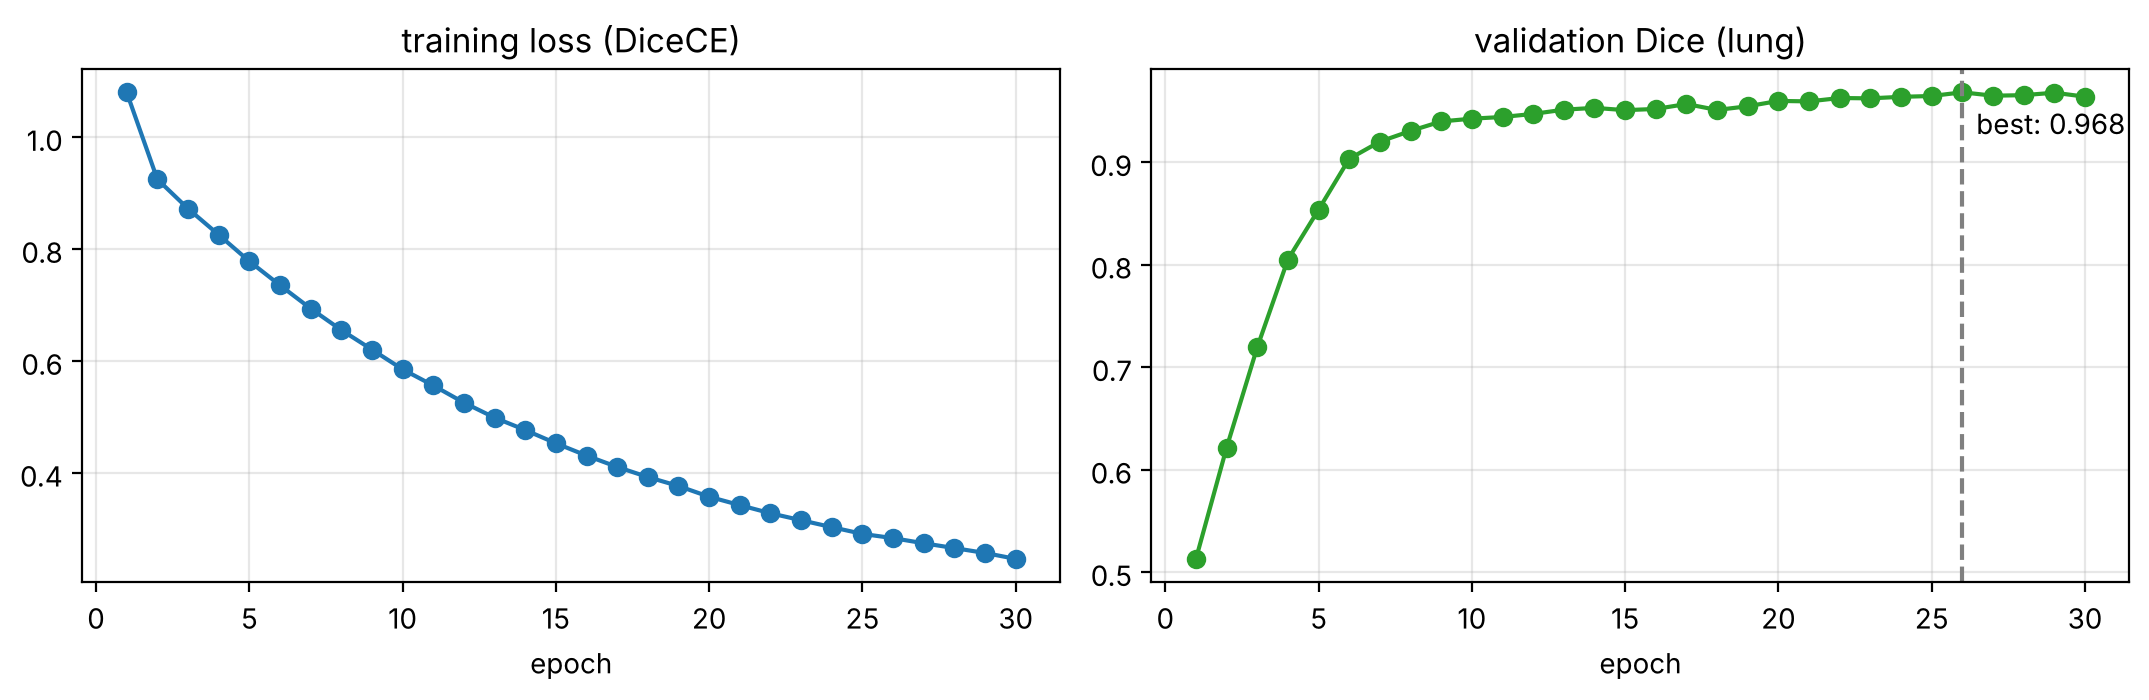

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(history["epoch"], history["train_loss"], marker="o"); axes[0].set_title("training loss (DiceCE)")
axes[1].plot(history["epoch"], history["val_dice"], marker="o", color="tab:green"); axes[1].set_title("validation Dice (lung)")
axes[1].axvline(best_epoch, ls="--", color="gray"); axes[1].annotate(f"best: {best_dice:.3f}", (best_epoch, best_dice), textcoords="offset points", xytext=(5, -15))
for ax in axes:
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

> 🧠 **Questions**
> 1. What would **underfitting** look like in these two plots? And **overfitting**?
> 2. The validation curve is noisier than the training curve. Why? (Think: size of the validation set, one number per epoch.)
> 3. The training loss is computed *during* the epoch, with augmentation, and the validation Dice *after* it, on clean images. Why can't we compare their values directly?
> 4. We pick the epoch with the best **validation** Dice. Is that validation Dice an unbiased estimate of the performance on new patients? What do we need?

**Answers.** 1. *Underfitting*: both training loss high/decreasing slowly and validation Dice low: the model (or the training time/learning rate) is not enough. *Overfitting*: training loss keeps
decreasing but validation Dice stops improving or gets worse: the model memorises. With augmentation and 600+ images, a small U-Net overfits slowly; you will typically see a plateau rather than a collapse.
2. The validation Dice is the mean over ~130-ish cases evaluated with weights that change at every epoch; a couple of difficult cases (artefacts, fibrosis) moving up or down shift the mean. The training loss is averaged over ~600 images and over the whole epoch (smoother).
3. Different quantities (loss vs Dice), different data (augmented vs clean), different weights (averaged over the epoch while it was learning vs final weights of the epoch).
4. No: selecting the best epoch on the validation set is a decision *made with* validation data, so the best score is optimistic (selection bias, "winner's curse"). The held-out **test set** (fold 9), used only once at the end, gives the unbiased number: day 3.

> 🔍 **Explore:** a mean validation Dice of 0.97 hides a lot. In part 8 you will see *which* cases are hard. Before that, guess: which kind of slices (top of the lungs? bottom, near the diaphragm? lungs with big nodules or effusions?) will be the worst?

## Part 8 - Looking at the predictions (about 20 min)
A number is never enough in medical imaging: we must *look*. We load the **best** weights (not the last epoch) and predict the whole validation set.

(18, 256, 256) (18, 256, 256) (18, 256, 256)


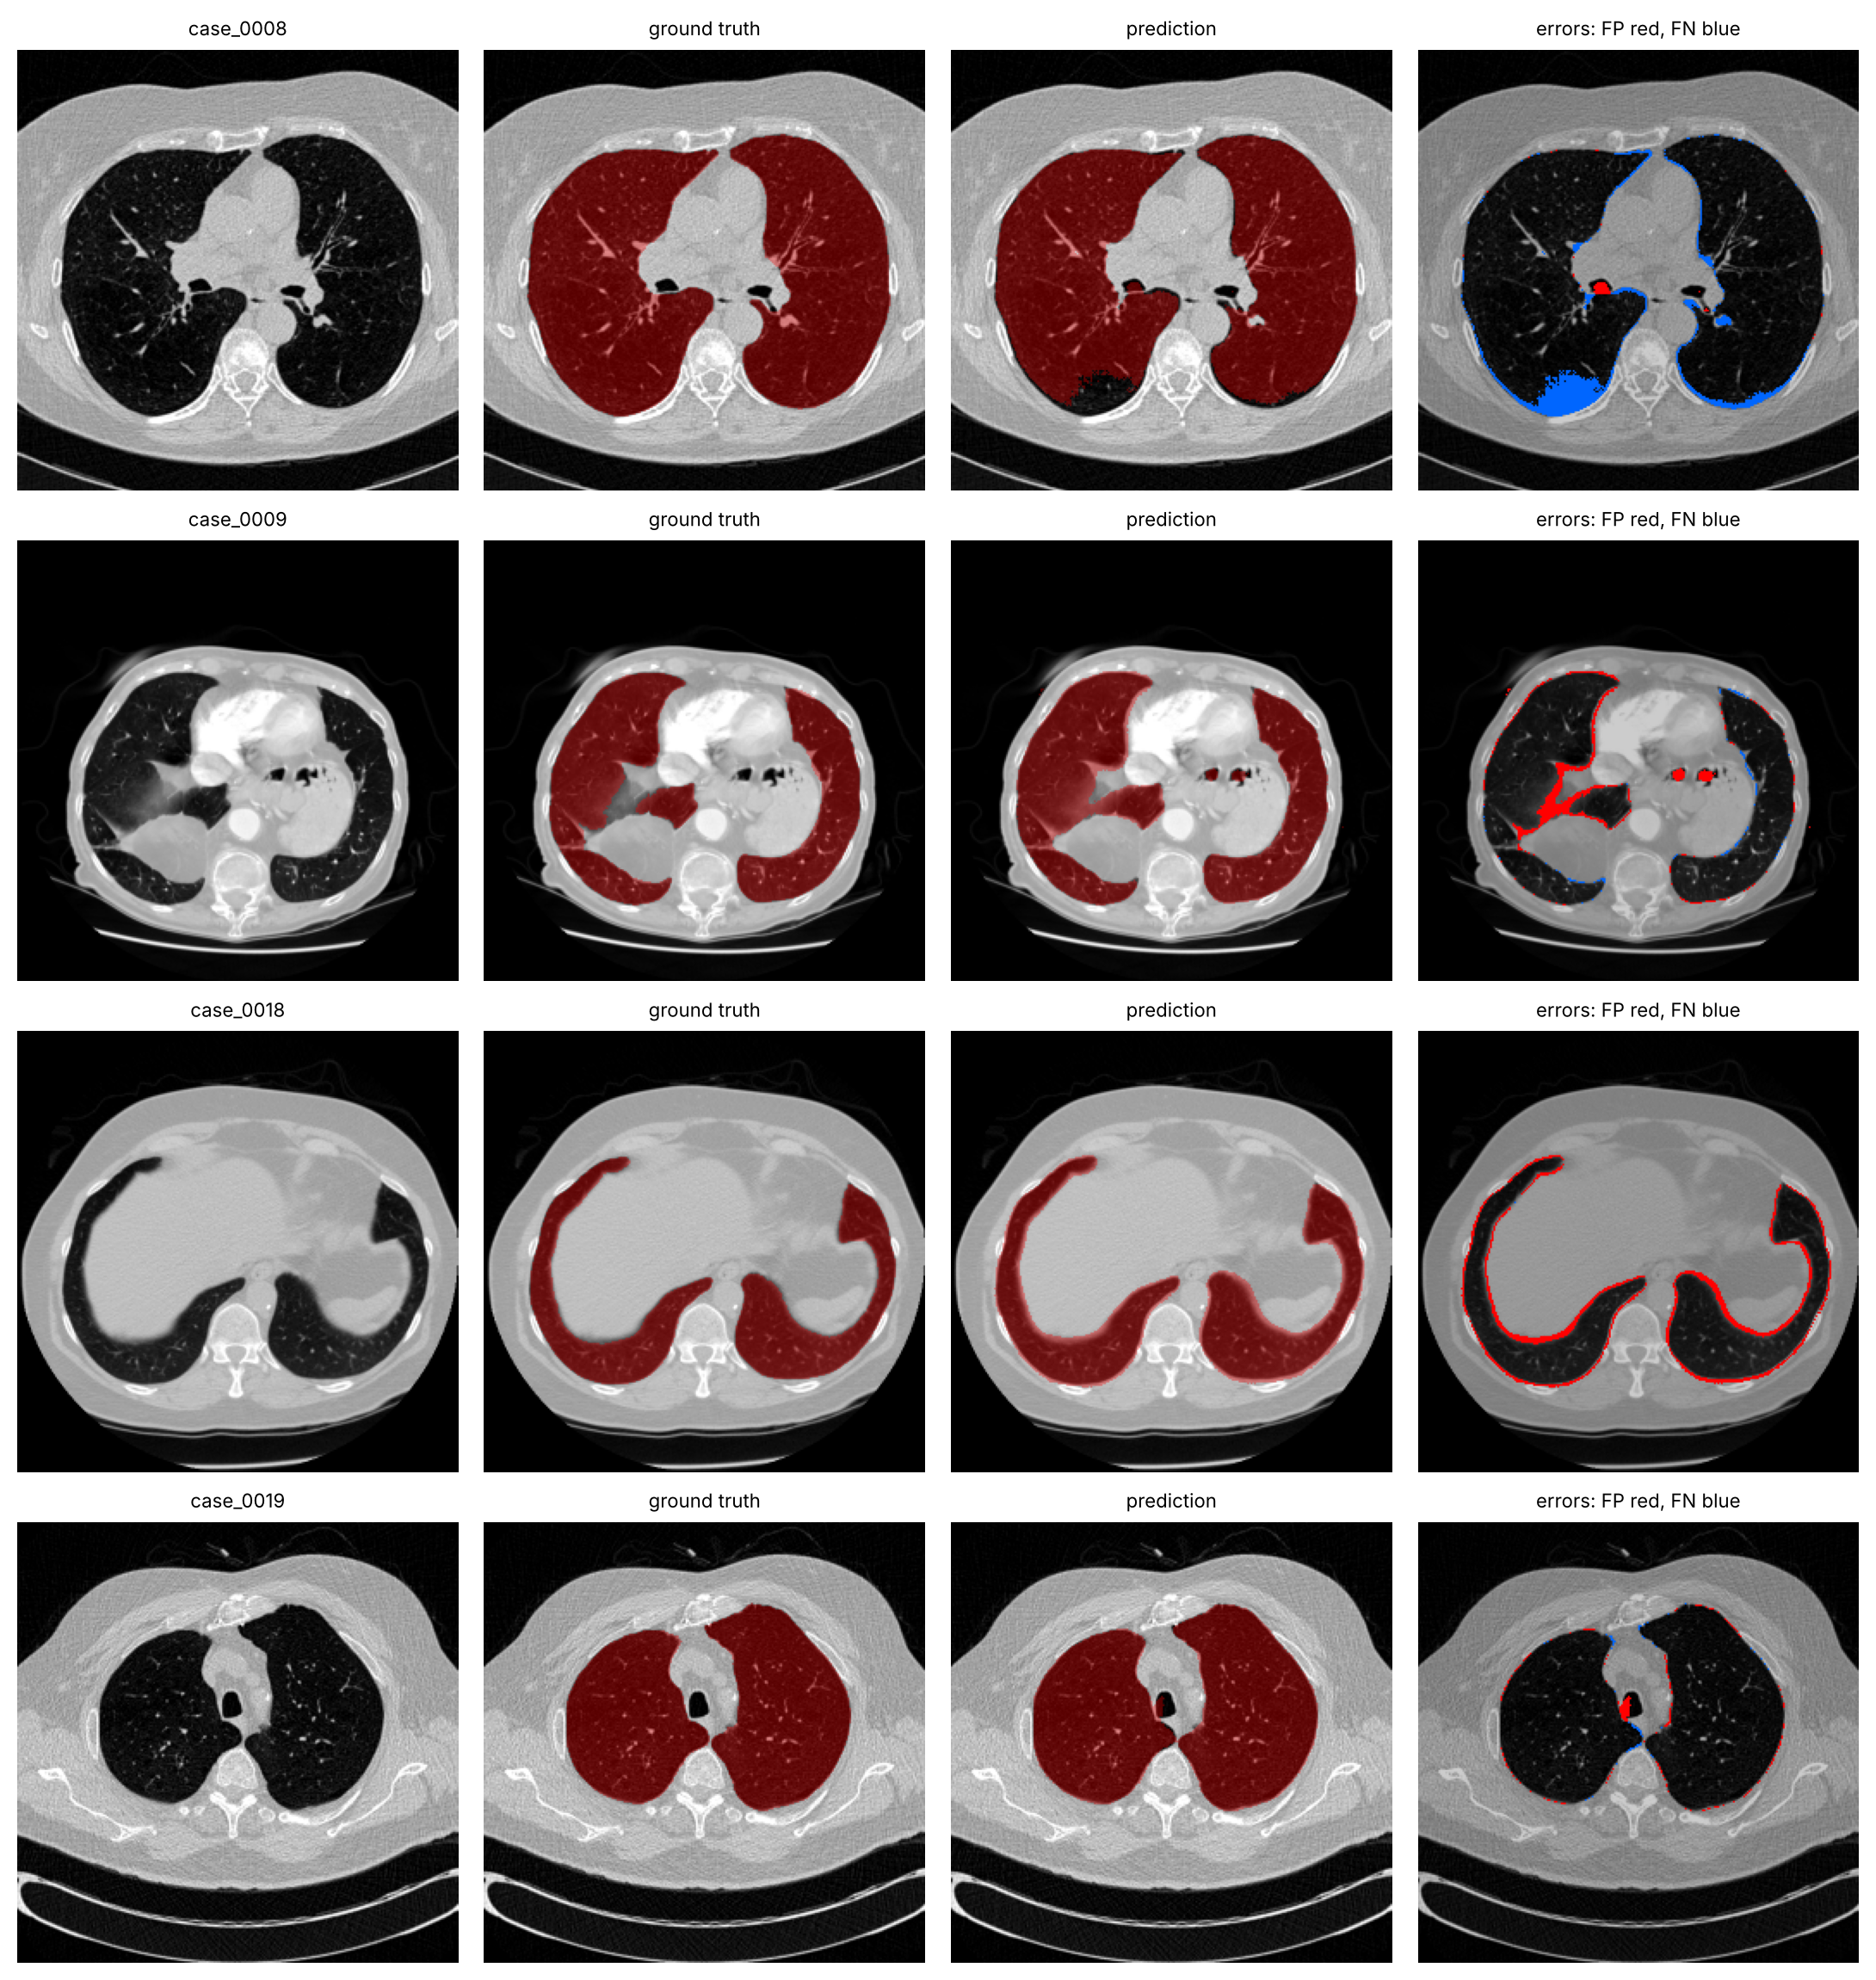

In [46]:
model.load_state_dict(torch.load(CKPT_PATH, map_location=device, weights_only=True))
model.eval()


@torch.no_grad()
def predict_loader(model, loader, device):
    """Predict a whole loader. Returns images, ground truths and hard predictions as numpy arrays [N, H, W]."""
    model.eval()
    images, gts, preds = [], [], []
    for batch in loader:
        logits = model(batch["image"].to(device))
        images.append(batch["image"][:, 0].numpy())
        gts.append(batch["label"][:, 0].numpy().astype(np.uint8))
        preds.append(logits.argmax(dim=1).cpu().numpy().astype(np.uint8))   # same as AsDiscrete(argmax=True) on each item
    return np.concatenate(images), np.concatenate(gts), np.concatenate(preds)


val_images, val_gts, val_preds = predict_loader(model, val_loader, device)
val_ids = [f["case_id"] for f in val_files]            # the val loader does not shuffle: same order as the files
print(val_images.shape, val_gts.shape, val_preds.shape)


def show_cases(idx, cols=("image", "ground truth", "prediction", "errors")):
    """One row per case: image | ground truth | prediction | error map (red = false positive, blue = false negative)."""
    fig, axes = plt.subplots(len(idx), 4, figsize=(11, 2.9 * len(idx)), squeeze=False)
    for row, i in zip(axes, idx):
        img, gt, pr = val_images[i], val_gts[i], val_preds[i]
        row[0].imshow(img.T, cmap="gray", vmin=0, vmax=1)
        show_overlay(row[1], img, gt, "ground truth")
        show_overlay(row[2], img, pr, "prediction")
        err = np.stack([img * 0.8] * 3, axis=-1)
        err[(pr == 1) & (gt == 0)] = [1.0, 0.0, 0.0]        # false positive: we predicted lung, it is not
        err[(pr == 0) & (gt == 1)] = [0.0, 0.4, 1.0]        # false negative: lung we missed
        row[3].imshow(err.transpose(1, 0, 2))
        row[3].set_title("errors: FP red, FN blue", fontsize=8)
        row[0].set_title(val_ids[i], fontsize=8)
        for ax in row: ax.axis("off")
    plt.tight_layout(); plt.show()


show_cases(list(range(min(4, len(val_ids)))))

### ✏️ Exercise 8.1 - Per-case Dice and the three worst cases
The mean Dice from the training loop hides the distribution. Compute the Dice **of every validation case** from the numpy arrays `val_gts` and `val_preds`
(shape `[N, H, W]`, values 0/1), then find the 3 worst. We use a tiny `eps` to avoid dividing by zero.

<details>
<summary>💡 Hint 1</summary>

Sum over the two image axes only (`axis=(1, 2)`), so that you get one number per case.

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`inter = (val_preds * val_gts).sum(axis=(1, 2))`, `dice = 2 * inter / (val_preds.sum(axis=(1, 2)) + val_gts.sum(axis=(1, 2)) + eps)`. The worst: `np.argsort(case_dice)[:3]` (sorted from the smallest value).

</details>

In [47]:
eps = 1e-8
inter = (val_preds * val_gts).sum(axis=(1, 2))
case_dice = 2 * inter / (val_preds.sum(axis=(1, 2)) + val_gts.sum(axis=(1, 2)) + eps)
worst = np.argsort(case_dice)[:3]
print(f"per-case Dice: mean {case_dice.mean():.4f} | median {np.median(case_dice):.4f} | min {case_dice.min():.4f}")
print("worst cases:", [(val_ids[i], round(float(case_dice[i]), 3)) for i in worst])

per-case Dice: mean 0.9684 | median 0.9798 | min 0.9126
worst cases: [('case_0018', 0.913), ('case_0059', 0.929), ('case_0038', 0.932)]


In [48]:
# Check 8.1
assert case_dice.shape == (len(val_ids),) and len(worst) == min(3, len(val_ids))
assert case_dice.min() >= 0 and case_dice.max() <= 1.0 + 1e-6
assert case_dice[worst[0]] == case_dice.min()
assert abs(case_dice.mean() - best_dice) < 1e-3, "the mean of your per-case Dice should equal the best validation Dice from the training loop"
print("✅ Exercise 8.1 passed: the per-case mean matches what DiceMetric reported")

✅ Exercise 8.1 passed: the per-case mean matches what DiceMetric reported


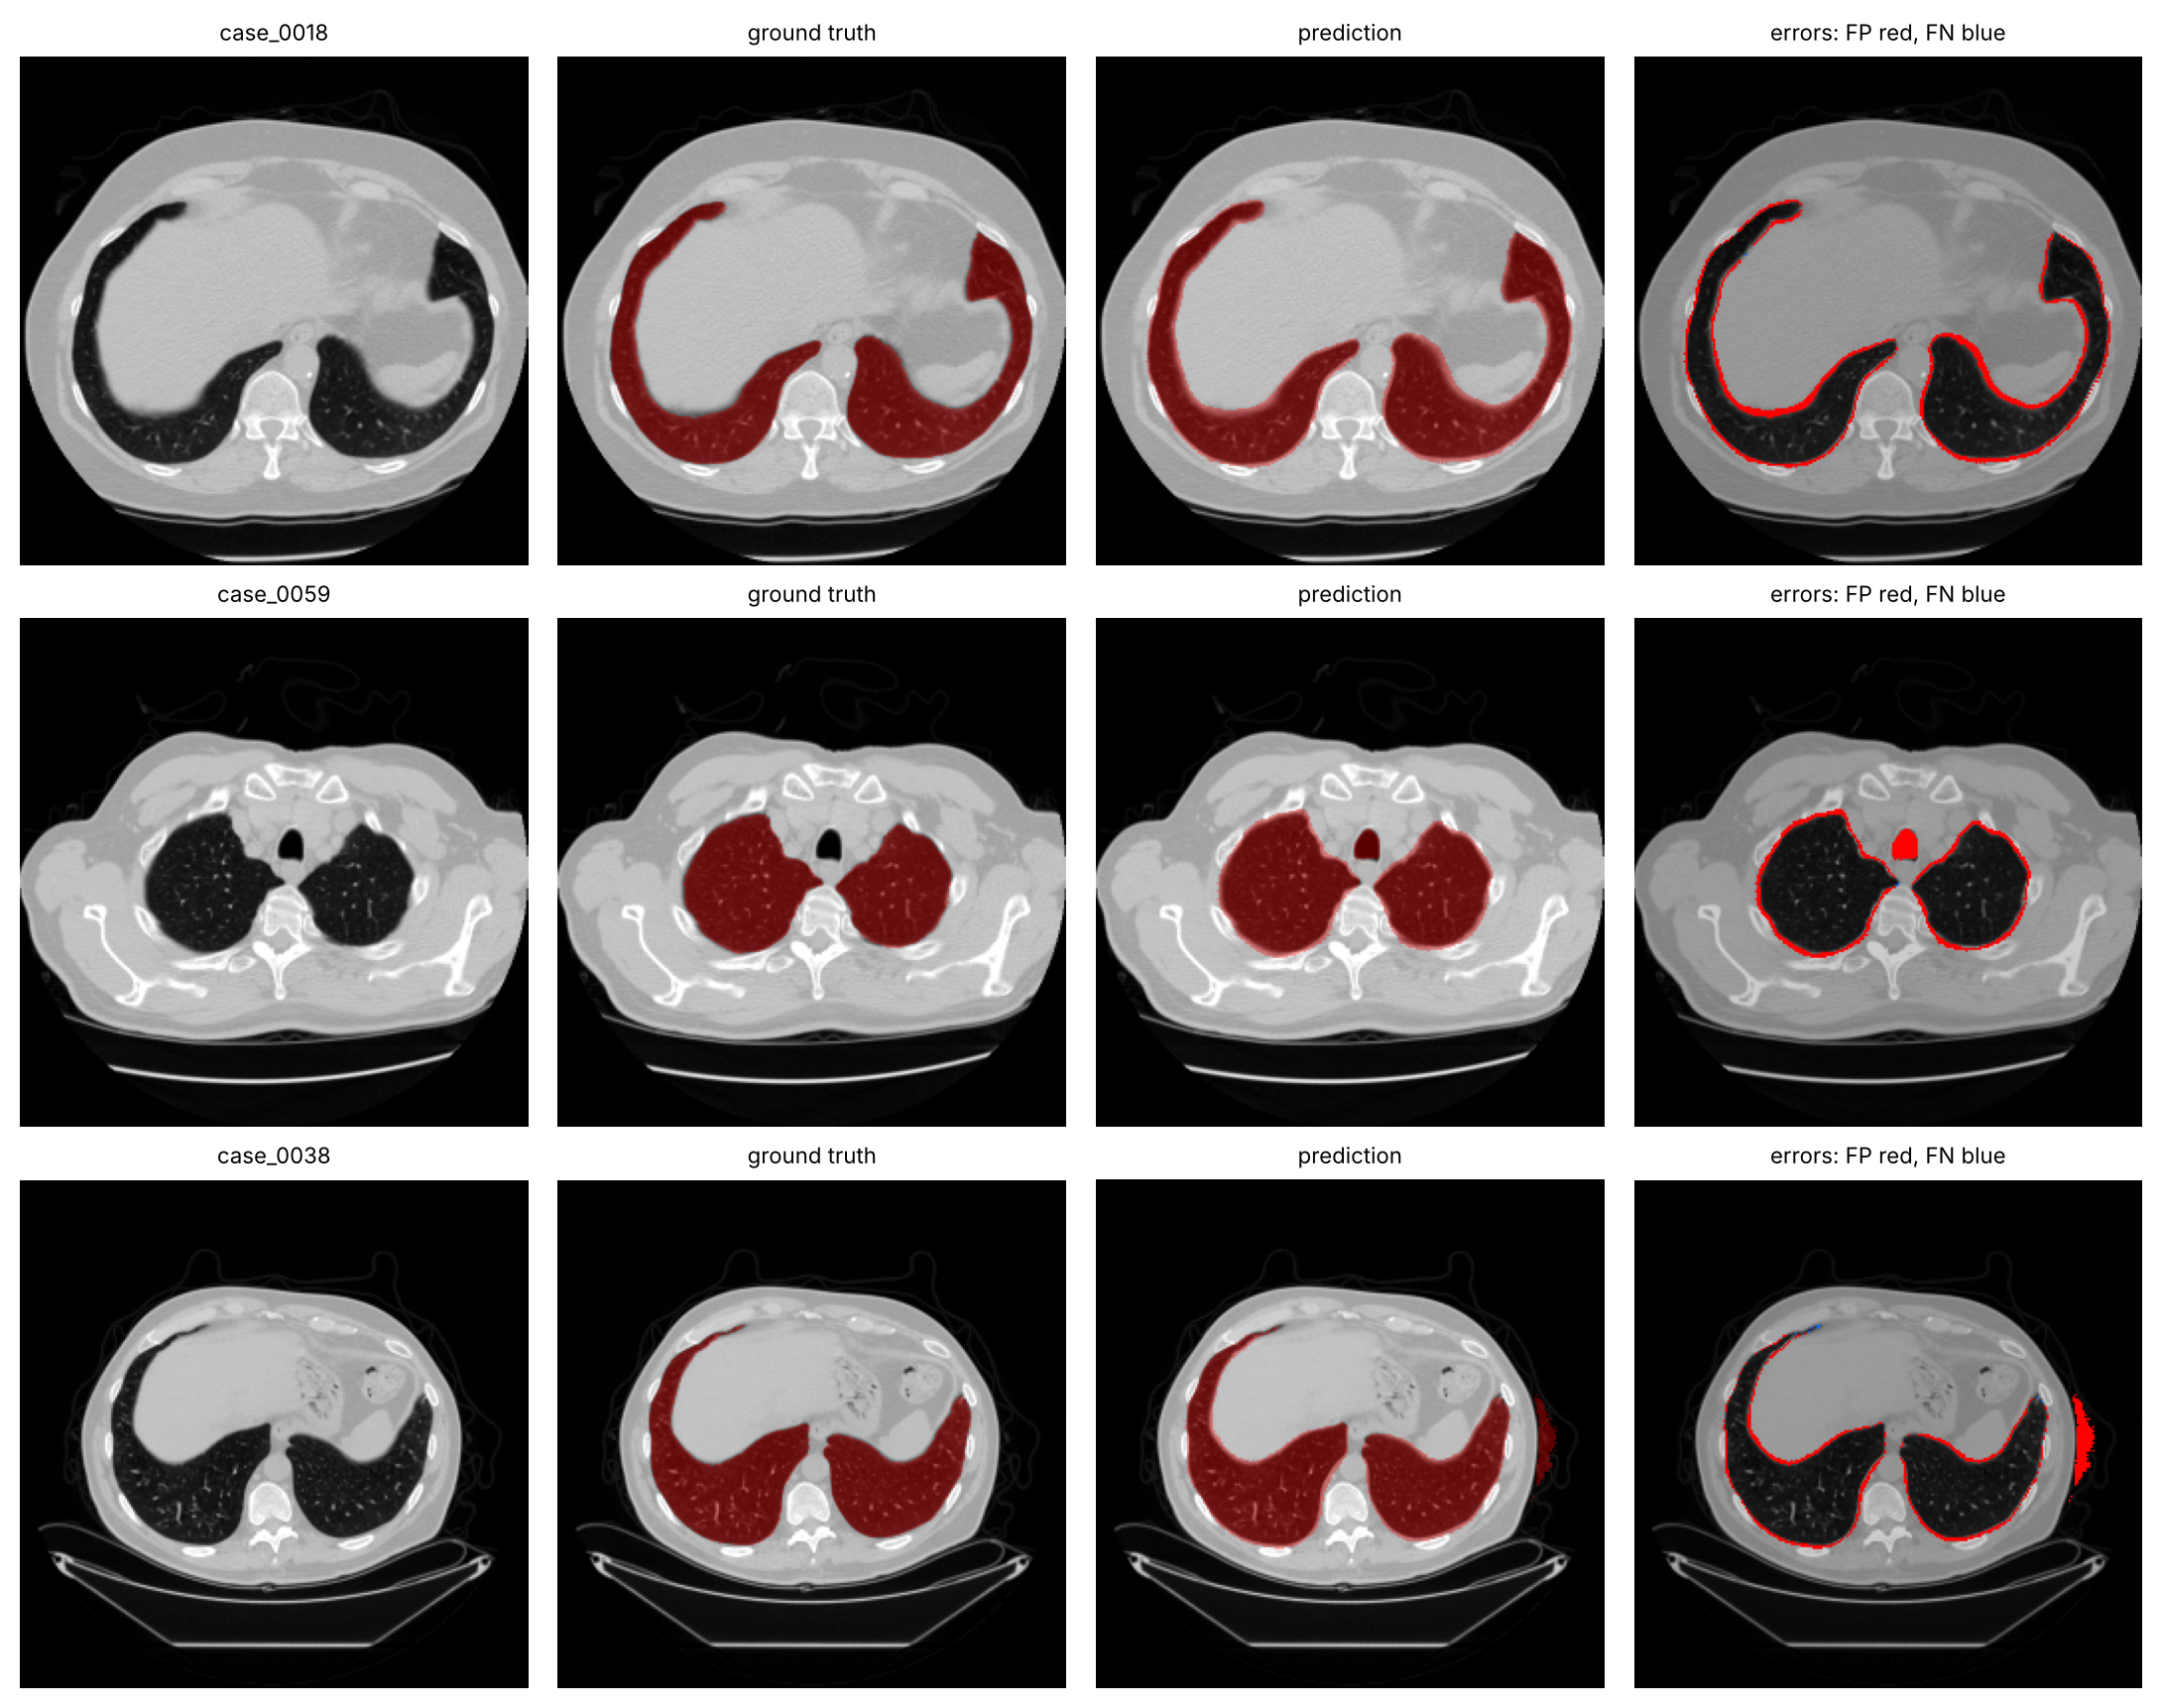

In [49]:
show_cases(list(worst))

> 🧠 **Questions**
> 1. Describe the errors of the worst cases: false positives, false negatives, where in the image? Is the *model* wrong, or could the *label* be wrong?
> 2. Why do we report the median (and look at the minimum) next to the mean?
> 3. A clinician plans radiotherapy using this mask. Which error is worse, FP or FN? (It depends on the application. Day 3: more metrics, HD95 and area in cm2.)

**Answers.** 1. Typical failures: slices near the top (apex) or the bottom (diaphragm, where lung is partly cut off and merges with liver/spleen), lungs with large
consolidations, pleural effusion or tumours (dense, no longer "dark"), airways or trachea included/excluded, artefacts; and the *silver-standard* labels from an algorithm can themselves be wrong
(so the "error" may be the label's). 2. The distribution is skewed: a few failures drag the mean down; the median describes the typical case, the minimum describes the worst-case
behaviour, and in medicine the worst case often matters most. 3. Application dependent: for a lung volume/size estimate FP and FN both bias it; for treatment planning, a false negative
could mean untreated tissue, a false positive irradiated healthy lung. The same Dice can hide very different clinical consequences.

## Part 9 - Save the model in the course format (about 15 min)
A model is more than weights: to use it later (day 3 evaluation, day 4 packaging, day 5 web app) somebody must know **which architecture** to build,
**which pre-processing** to apply and **how good** it is. Our contract is a folder with two files:

```
WORK_DIR/models/<MODEL_NAME>/
    model.pt       the state_dict (weights only)
    config.json    arch + arch_kwargs + preprocessing + labels + metrics + who/when
```
`arch` is the *name of a class in `monai.networks.nets`*: the app rebuilds the network with `getattr(monai.networks.nets, arch)(**arch_kwargs)`.

> ⚠️ **Pitfall (training-serving skew):** if the web app used a different HU window or image size than the training pipeline, the model would silently perform
> much worse. That is why `config.json` stores the pre-processing, and why we take the numbers from the same place used for training.

### ✏️ Exercise 9.1 - Write `config.json`
Fill in the dictionary. The HU window must be the one used by `get_transforms`.

<details>
<summary>💡 Hint 1</summary>

`arch` is a string: the class name you used in exercise 3.1. The HU window is in the defaults of `get_transforms(img_size, hu_min=..., hu_max=...)`.

</details>

<details>
<summary>💡 Hint 2 (almost the solution)</summary>

`"arch": "UNet"`, `"hu_min": -1000, "hu_max": 400`, `"val_dice": round(best_dice, 4)`, `"trained_by": STUDENT_NAME`.

</details>

In [50]:
model_dir = WORK_DIR / "models" / MODEL_NAME
model_dir.mkdir(parents=True, exist_ok=True)

config = {
    "name": MODEL_NAME,
    "arch": "UNet",
    "arch_kwargs": arch_kwargs,
    "preprocessing": {"hu_min": -1000, "hu_max": 400, "img_size": [IMG_SIZE, IMG_SIZE]},
    "labels": {"0": "background", "1": "lung"},
    "metrics": {"val_dice": round(best_dice, 4)},
    "trained_by": STUDENT_NAME,
    "date": dt.date.today().isoformat(),
}

# the weights of the BEST epoch, and the config, go into the folder
model.load_state_dict(torch.load(CKPT_PATH, map_location=device, weights_only=True))
torch.save(model.state_dict(), model_dir / "model.pt")
(model_dir / "config.json").write_text(json.dumps(config, indent=2))
print(json.dumps(config, indent=2))

{
  "name": "unet-baseline",
  "arch": "UNet",
  "arch_kwargs": {
    "spatial_dims": 2,
    "in_channels": 1,
    "out_channels": 2,
    "channels": [
      16,
      32,
      64,
      128,
      256
    ],
    "strides": [
      2,
      2,
      2,
      2
    ],
    "num_res_units": 2
  },
  "preprocessing": {
    "hu_min": -1000,
    "hu_max": 400,
    "img_size": [
      256,
      256
    ]
  },
  "labels": {
    "0": "background",
    "1": "lung"
  },
  "metrics": {
    "val_dice": 0.9684
  },
  "trained_by": "your name",
  "date": "2026-11-18"
}


In [51]:
# Check 9.1
import inspect
defaults = inspect.signature(get_transforms).parameters
assert hasattr(monai.networks.nets, config["arch"]), f"{config['arch']!r} is not a class of monai.networks.nets"
assert config["preprocessing"]["hu_min"] == defaults["hu_min"].default and config["preprocessing"]["hu_max"] == defaults["hu_max"].default, \
    "the HU window in the config must be the one used for training (training-serving skew!)"
assert config["preprocessing"]["img_size"] == [IMG_SIZE, IMG_SIZE]
assert isinstance(config["metrics"]["val_dice"], float) and 0 <= config["metrics"]["val_dice"] <= 1
assert isinstance(config["trained_by"], str) and config["trained_by"].strip() not in ("", "____")
print("✅ Exercise 9.1 passed")

✅ Exercise 9.1 passed


### Reload with the course loader and verify
These two functions are **the same in notebooks 04-06**: `find_model_dirs` looks for model folders, `load_model` rebuilds the network from
`config.json`. If the reloaded model gives different predictions than the one in memory, something is wrong with the saving: we assert that it does not.

In [52]:
import json, monai, torch

def find_model_dirs():
    """All model folders (config.json + model.pt) we can see, most specific first."""
    roots = [os.environ.get("HI_MODEL_DIR"), WORK_DIR / "models", "/kaggle/input", DATA_DIR / "pretrained"]
    found = []
    for r in roots:
        if r and Path(r).exists():
            dirs = [p.parent for p in Path(r).rglob("config.json") if (p.parent / "model.pt").exists()]
            # within one place: the most recently saved model first
            found += sorted(dirs, key=lambda d: (d / "model.pt").stat().st_mtime, reverse=True)

    def is_binary_2d(d):   # the course contract: 2D, 1 input channel (HU window), 2 output channels
        k = json.loads((d / "config.json").read_text()).get("arch_kwargs", {})
        return (k.get("spatial_dims"), k.get("in_channels"), k.get("out_channels")) == (2, 1, 2)

    return [d for d in found if is_binary_2d(d)]

def load_model(model_dir, device="cpu"):
    cfg = json.loads((Path(model_dir) / "config.json").read_text())
    net = getattr(monai.networks.nets, cfg["arch"])(**cfg["arch_kwargs"])
    net.load_state_dict(torch.load(Path(model_dir) / "model.pt", map_location=device, weights_only=True))
    return net.to(device).eval(), cfg

In [53]:
print("model folders found:", [str(p) for p in find_model_dirs()])
reloaded, cfg = load_model(model_dir, device)
model.eval()
with torch.no_grad():
    same = torch.allclose(model(xv), reloaded(xv), atol=1e-5)
assert same, "the reloaded model does not reproduce the predictions of the trained one"
assert cfg["metrics"]["val_dice"] == config["metrics"]["val_dice"]
print("✅ The reloaded model gives identical predictions. Your model is ready for days 3-5.")

model folders found: ['/tmp/hi_real2/models/unet-baseline', '/home/claude/data/real_test/pretrained/unet-baseline']


✅ The reloaded model gives identical predictions. Your model is ready for days 3-5.


### Get the model out of the notebook (and keep it!)
The notebook's disk is **temporary**: when the Kaggle/Colab session ends, files may disappear. We zip the folder and secure it:

* **Kaggle:** files in `/kaggle/working` appear in the *Output* panel (right side / *Data* tab) and are **kept when you "Save Version"** (use *Save & Run All* or *Quick Save*): you can then
  attach that output to a new notebook through *Add Input* -> *Notebook Output Files*. You can also download the zip from the file browser (`...` menu -> *Download*) and upload it
  as a private **Kaggle Dataset** (*Create -> New Dataset*); datasets are attached to any later notebook and `find_model_dirs()` finds them under `/kaggle/input`.
* **Colab:** open the *Files* panel (folder icon), right-click the zip -> *Download*; or run `from google.colab import files; files.download("<path-to-zip>")`. Colab storage is wiped at the end of the session.
* **Why we need it:** day 3 evaluates it on the test set, day 4 packages it, day 5 the web app loads it. **Safety net:** the course dataset ships the teachers' model (`pretrained/unet-baseline`):
  if yours is lost or poor, notebooks 04-06 still work.

In [54]:
zip_path = shutil.make_archive(str(WORK_DIR / MODEL_NAME), "zip", root_dir=model_dir.parent, base_dir=MODEL_NAME)
print(f"zip: {zip_path} ({Path(zip_path).stat().st_size / 1e6:.1f} MB)")
assert Path(zip_path).exists()

zip: /tmp/hi_real2/unet-baseline.zip (6.0 MB)


**You now have a trained model. Congratulations!** Parts 10-11 are optional: experiments and challenges for groups that are ahead (or for the next break).

## Part 10 - 🔍 Experiments (optional, about 20-30 min)
What happens if you change one thing? `quick_run` trains a **fresh** U-Net for a few epochs (`EXP_EPOCHS`) with the settings you choose and returns its history.
The best way to learn what each setting does is to change **one** at a time and compare the curves with the baseline.

In [55]:
def quick_run(name, lr=LR, batch_size=BATCH_SIZE, augment=True, loss="dicece", channels=(16, 32, 64, 128, 256),
              n_classes=2, epochs=EXP_EPOCHS, datasets=None):
    """Train a fresh U-Net for a few epochs. Returns {"name", "train_loss", "val_dice", "best", "params"}."""
    set_determinism(seed=42)
    if datasets is None:
        tr_ds = train_ds if augment else CacheDataset(train_files, transform=val_tf, cache_rate=1.0, num_workers=NUM_WORKERS)
        va_ds = val_ds
    else:
        tr_ds, va_ds = datasets
    tr = DataLoader(tr_ds, batch_size=batch_size, shuffle=True, num_workers=NUM_WORKERS)
    va = DataLoader(va_ds, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
    kwargs = {**arch_kwargs, "channels": list(channels), "strides": [2] * (len(channels) - 1), "out_channels": n_classes}
    net = UNet(**kwargs).to(device)
    loss_fns = {"dice": DiceLoss(to_onehot_y=True, softmax=True),
                "dicece": DiceCELoss(to_onehot_y=True, softmax=True),
                "ce": lambda lg, y: F.cross_entropy(lg, y[:, 0].long())}
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    metric = DiceMetric(include_background=False, reduction="mean")
    pp, pl = AsDiscrete(argmax=True, to_onehot=n_classes), AsDiscrete(to_onehot=n_classes)
    run = {"name": name, "train_loss": [], "val_dice": [], "params": sum(p.numel() for p in net.parameters())}
    for _ in range(epochs):
        run["train_loss"].append(train_one_epoch(net, tr, opt, loss_fns[loss], device))
        run["val_dice"].append(validate(net, va, metric, device, post_pred=pp, post_label=pl))
    run["best"] = max(run["val_dice"])
    print(f"{name:28s} best val Dice {run['best']:.4f} | final loss {run['train_loss'][-1]:.3f} | {run['params']:,} params")
    return run


def compare_runs(runs):
    plt.figure(figsize=(6, 3.6))
    for r in runs:
        plt.plot(range(1, len(r["val_dice"]) + 1), r["val_dice"], marker="o", label=r["name"])
    plt.xlabel("epoch"); plt.ylabel("val Dice"); plt.legend(); plt.grid(alpha=0.3); plt.show()

### 🔍 Explore - learning rate and batch size
* Predict first: which of `lr = 1e-2`, `1e-3`, `1e-4` will be best after only a few epochs? Why might the best for 6 epochs differ from the best for 30?
* With a bigger batch the gradient is less noisy but there are fewer updates per epoch. What do you expect from `batch_size=4` vs `32`?

baseline lr=1e-3             best val Dice 0.9035 | final loss 0.736 | 1,625,161 params


lr=1e-2                      best val Dice 0.9285 | final loss 0.194 | 1,625,161 params


lr=1e-4                      best val Dice 0.4984 | final loss 0.975 | 1,625,161 params


batch size 4                 best val Dice 0.9548 | final loss 0.334 | 1,625,161 params


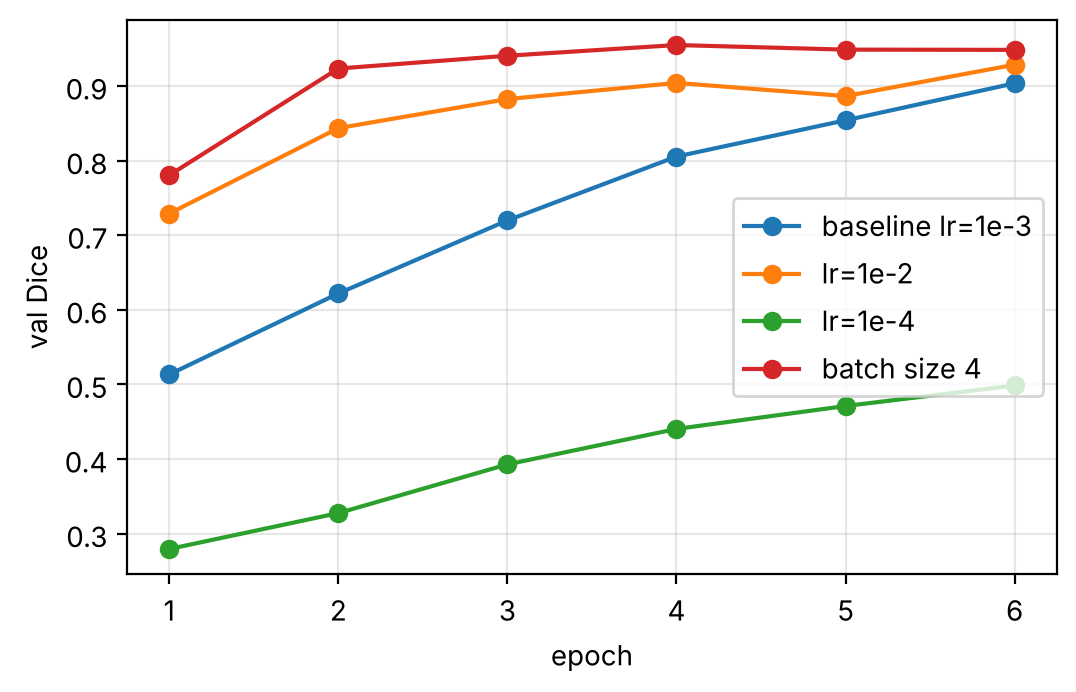

In [56]:
runs = [quick_run("baseline lr=1e-3"),
        quick_run("lr=1e-2", lr=1e-2),
        quick_run("lr=1e-4", lr=1e-4),
        quick_run("batch size 4", batch_size=4)]
compare_runs(runs)

### 🔍 Explore - augmentation, loss, model size
* **Without augmentation**: on a small dataset it is expected to overfit faster. After a few epochs the difference is small: why? What would you look at to see it (the *gap* between training and validation)?
* **Loss**: `"dice"` alone vs `"ce"` alone vs `"dicece"`. Which learns fastest in the first epoch?
* **Smaller network**: `channels=(8, 16, 32, 64, 128)` has ~4x fewer parameters. Is the lung problem hard enough to need the big one? (For deployment on a hospital server without GPU this matters.)

baseline                     best val Dice 0.9035 | final loss 0.736 | 1,625,161 params


Loading dataset:   0%|          | 0/63 [00:00<?, ?it/s]

Loading dataset:  21%|██        | 13/63 [00:00<00:00, 124.81it/s]

Loading dataset:  44%|████▍     | 28/63 [00:00<00:00, 133.87it/s]

Loading dataset:  67%|██████▋   | 42/63 [00:00<00:00, 135.91it/s]

Loading dataset:  90%|█████████ | 57/63 [00:00<00:00, 140.63it/s]

Loading dataset: 100%|██████████| 63/63 [00:00<00:00, 138.92it/s]

no augmentation              best val Dice 0.9066 | final loss 0.732 | 1,625,161 params


Dice loss only               best val Dice 0.8054 | final loss 0.394 | 1,625,161 params


CE loss only                 best val Dice 0.9035 | final loss 0.349 | 1,625,161 params


small U-Net (8..128)         best val Dice 0.6931 | final loss 1.030 | 406,977 params


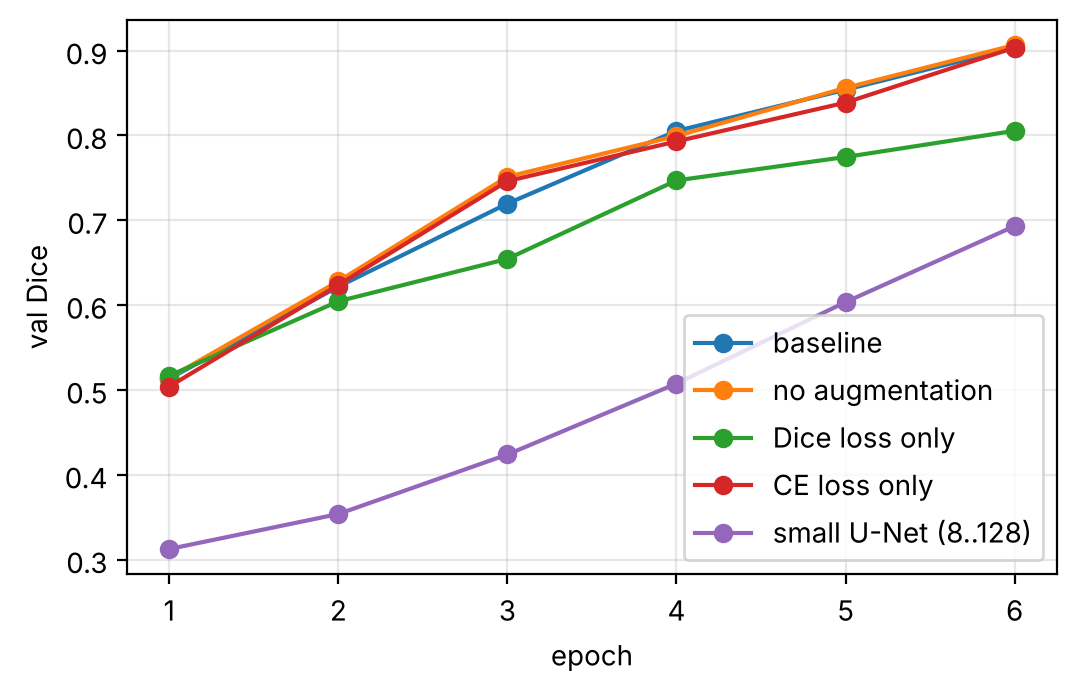

In [57]:
runs2 = [quick_run("baseline", ),
         quick_run("no augmentation", augment=False),
         quick_run("Dice loss only", loss="dice"),
         quick_run("CE loss only", loss="ce"),
         quick_run("small U-Net (8..128)", channels=(8, 16, 32, 64, 128))]
compare_runs(runs2)

**Teacher notes (what students typically see, real data, 6 epochs on a T4).** `lr=1e-2` is jumpy and often best epoch is not the last; `1e-4` is clearly slower after 6 epochs
(it needs more epochs, not a worse model); batch size 4 makes more updates per epoch and often wins early, but each epoch is slower on a GPU (low utilisation).
No augmentation looks the same or even better after 6 epochs (training and validation come from the same distribution and the network has not yet overfit); its cost appears with
longer training and, above all, with distribution shift (day 3 robustness). CE alone starts slowly/predicts almost only background at first; Dice alone is unstable in the first steps; DiceCE is smoothest.
The 4x smaller network usually loses < 0.5 Dice points: lungs are easy. Numbers vary: ask students to compare *curves*, not decimals (single seed!). Advanced: repeat with another seed to see the noise.

## Part 11 - 🚀 Challenges and 🌶️ going further (optional)
Each challenge is independent. Use `quick_run`-style short runs (`EXP_EPOCHS`) to test your code, **then** (if you want) run it for real.

### 🚀 Challenge A - Learning-rate schedule (cosine) and mixed precision
1. **Cosine annealing**: start with `lr=1e-3` and decay smoothly to ~0 at the last epoch: big steps first, fine adjustments at the end. Use `torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)` and call `scheduler.step()` **once per epoch**, after the optimiser's steps.
2. **Mixed precision (AMP)**: on a GPU, computing in float16 where safe makes training ~1.5-3x faster and uses less memory. Wrap the forward pass and loss in `torch.autocast`, scale the loss with a `torch.amp.GradScaler` before `backward`, and let the scaler do the step. Only enable it when `device.type == "cuda"`.

Write `train_one_epoch_amp(model, loader, optimizer, loss_fn, device, scaler)` and a short training loop with the scheduler. Print the learning rate at each epoch.
📚 https://pytorch.org/docs/stable/notes/amp_examples.html · https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.CosineAnnealingLR.html

<details>
<summary>💡 Hint</summary>

The step becomes: `with torch.autocast(device_type=device.type, enabled=use_amp): logits = model(x); loss = loss_fn(logits, y)`, then `scaler.scale(loss).backward()`, `scaler.step(optimizer)`, `scaler.update()`.

</details>

In [58]:
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)


def train_one_epoch_amp(model, loader, optimizer, loss_fn, device, scaler):
    model.train()
    total, n = 0.0, 0
    for batch in loader:
        x, y = batch["image"].to(device), batch["label"].to(device)
        optimizer.zero_grad()
        with torch.autocast(device_type=device.type, enabled=use_amp):
            logits = model(x)
            loss = loss_fn(logits, y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total += loss.item() * x.shape[0]
        n += x.shape[0]
    return total / n


torch.manual_seed(0)
net_a = new_model()
opt_a = torch.optim.Adam(net_a.parameters(), lr=LR)
sched_a = torch.optim.lr_scheduler.CosineAnnealingLR(opt_a, T_max=EXP_EPOCHS)
for epoch in range(1, EXP_EPOCHS + 1):
    loss_a = train_one_epoch_amp(net_a, train_loader, opt_a, loss_fn, device, scaler)
    dice_a = validate(net_a, val_loader, dice_metric, device)
    print(f"epoch {epoch} | lr {opt_a.param_groups[0]['lr']:.2e} | loss {loss_a:.4f} | val Dice {dice_a:.4f} | AMP {use_amp}")
    sched_a.step()
assert opt_a.param_groups[0]["lr"] < LR / 2, "the cosine schedule should have reduced the learning rate"

epoch 1 | lr 1.00e-03 | loss 1.1424 | val Dice 0.5875 | AMP False


epoch 2 | lr 9.33e-04 | loss 0.9257 | val Dice 0.7496 | AMP False


epoch 3 | lr 7.50e-04 | loss 0.8190 | val Dice 0.8222 | AMP False


epoch 4 | lr 5.00e-04 | loss 0.7583 | val Dice 0.8467 | AMP False


epoch 5 | lr 2.50e-04 | loss 0.7238 | val Dice 0.8614 | AMP False


epoch 6 | lr 6.70e-05 | loss 0.7091 | val Dice 0.8665 | AMP False


### 🚀 Challenge B - Early stopping with patience
Stop the training when the validation Dice has not improved for `patience` consecutive epochs, and keep the best weights. Write a small class `EarlyStopping`
with a method `step(value)` that returns `True` when it is time to stop, and test it on a fake sequence of validation scores *before* using it in a loop.

<details>
<summary>💡 Hint</summary>

Keep `best` and a counter `bad_epochs`; reset the counter when `value > best`, increase it otherwise; stop when `bad_epochs >= patience`.

</details>

In [59]:
class EarlyStopping:
    def __init__(self, patience=5):
        self.patience, self.best, self.bad_epochs = patience, -float("inf"), 0

    def step(self, value):
        if value > self.best:
            self.best, self.bad_epochs = value, 0
        else:
            self.bad_epochs += 1
        return self.bad_epochs >= self.patience


# unit test on a fake validation curve: the best value is 0.80 (epoch 3); epochs 4, 5, 6 do not beat it -> stop at epoch 6
stopper = EarlyStopping(patience=3)
decisions = [stopper.step(v) for v in [0.50, 0.70, 0.80, 0.79, 0.80, 0.78]]
assert decisions == [False, False, False, False, False, True], decisions

stopper, net_b = EarlyStopping(patience=2), new_model()
opt_b = torch.optim.Adam(net_b.parameters(), lr=LR)
for epoch in range(1, EXP_EPOCHS + 1):
    train_one_epoch(net_b, train_loader, opt_b, loss_fn, device)
    d = validate(net_b, val_loader, dice_metric, device)
    print(f"epoch {epoch} val Dice {d:.4f}")
    if stopper.step(d):
        print("early stop"); break

epoch 1 val Dice 0.4104


epoch 2 val Dice 0.5104


epoch 3 val Dice 0.5704


epoch 4 val Dice 0.5977


epoch 5 val Dice 0.6051


epoch 6 val Dice 0.6142


### 🚀 Challenge C - Log to TensorBoard
TensorBoard shows live curves and compares runs. Create `SummaryWriter(WORK_DIR / "runs" / "unet")`, call `writer.add_scalar("val/dice", value, epoch)` (and the loss, and the
learning rate) every epoch, and `writer.close()` at the end.
* **Colab / Jupyter:** run `%load_ext tensorboard` and then `%tensorboard --logdir outputs/runs` in a cell (the exact path = your `WORK_DIR / "runs"`).
* **Kaggle:** the in-notebook widget is unreliable: save the version, **download the `runs` folder** and run `tensorboard --logdir runs` on your laptop.

📚 https://pytorch.org/docs/stable/tensorboard.html

In [60]:
try:
    from torch.utils.tensorboard import SummaryWriter
except ImportError:   # tensorboard is not installed everywhere
    SummaryWriter = None
    print("tensorboard not installed: pip install tensorboard")

if SummaryWriter is not None:
    writer = SummaryWriter(WORK_DIR / "runs" / "unet")
    net_c = new_model()
    opt_c = torch.optim.Adam(net_c.parameters(), lr=LR)
    for epoch in range(1, EXP_EPOCHS + 1):
        loss_c = train_one_epoch(net_c, train_loader, opt_c, loss_fn, device)
        dice_c = validate(net_c, val_loader, dice_metric, device)
        writer.add_scalar("train/loss", loss_c, epoch)
        writer.add_scalar("val/dice", dice_c, epoch)
        writer.add_scalar("lr", opt_c.param_groups[0]["lr"], epoch)
    writer.close()
    event_files = list((WORK_DIR / "runs" / "unet").glob("events.*"))
    assert event_files, "no TensorBoard event file was written"
    print("logged to", WORK_DIR / "runs" / "unet", "-", len(event_files), "event file(s)")

logged to /tmp/hi_real2/runs/unet - 1 event file(s)


### 🚀 Challenge D - A 3-class model (right lung / left lung / trachea)
The original labels have **4 values**: 0 background, 1 right lung, 2 left lung, 3 trachea/main airways. Train a model that predicts all of them.
What changes compared to the binary pipeline?
* **Transforms**: do not merge the labels (no `Lambdad(lungs_only)`).
* **Network and loss**: `out_channels=4`; `DiceCELoss(to_onehot_y=True, softmax=True)` works unchanged.
* **Post-processing**: `AsDiscrete(argmax=True, to_onehot=4)` and `AsDiscrete(to_onehot=4)`.
* **Metric**: `DiceMetric(include_background=False)` now returns the mean over the 3 foreground classes (use `reduction="mean_batch"` to get one value per class!).
* `quick_run(..., n_classes=4, datasets=(train_ds_mc, val_ds_mc))` does all of this for you once you provide the datasets.

> ⚠️ **Pitfall: flip augmentation.** A horizontal flip (`RandFlipd`) is harmless for "lung vs not lung", but with *left* and *right* classes the flipped image shows the "right lung"
> on the patient's left: the label is now anatomically wrong, and the network learns nonsense (it must tell left from right using the heart, stomach bubble, liver). Either **no flips**,
> or flip *and swap labels 1 <-> 2*. Look at the demo in the solution below.

nvImageCodec is not available; skipping pydicom decoder plugin registration.


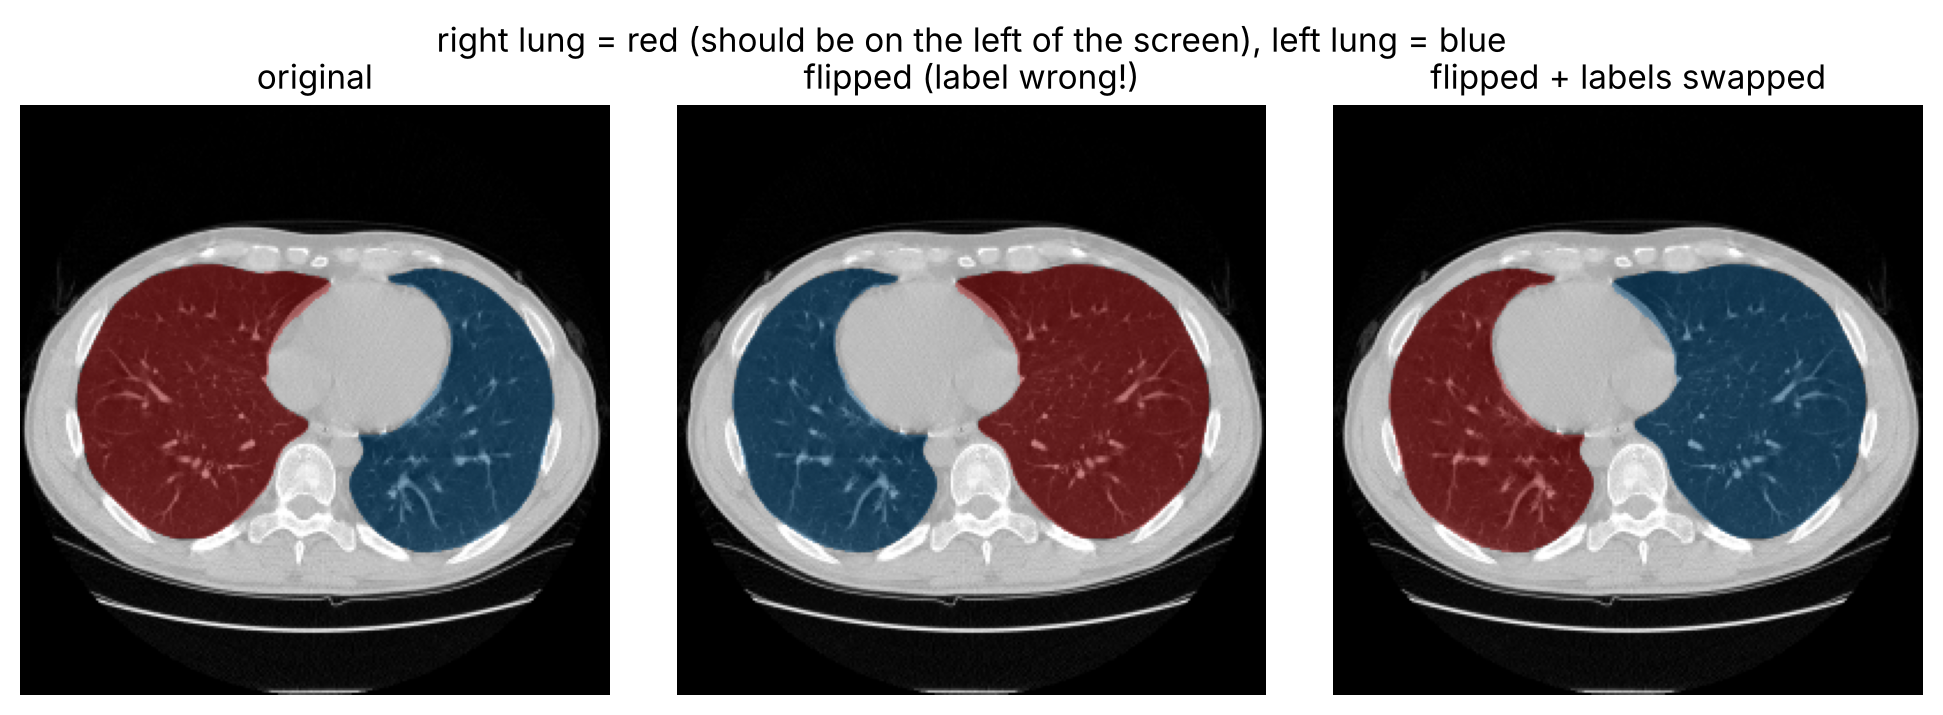

nvImageCodec is not available; skipping pydicom decoder plugin registration.


Loading dataset:   0%|          | 0/63 [00:00<?, ?it/s]

Loading dataset:  25%|██▌       | 16/63 [00:00<00:00, 151.23it/s]

Loading dataset:  54%|█████▍    | 34/63 [00:00<00:00, 162.16it/s]

Loading dataset:  81%|████████  | 51/63 [00:00<00:00, 165.20it/s]

Loading dataset: 100%|██████████| 63/63 [00:00<00:00, 165.21it/s]


nvImageCodec is not available; skipping pydicom decoder plugin registration.


Loading dataset:   0%|          | 0/18 [00:00<?, ?it/s]

Loading dataset:  89%|████████▉ | 16/18 [00:00<00:00, 150.47it/s]

Loading dataset: 100%|██████████| 18/18 [00:00<00:00, 156.25it/s]

3-class U-Net                best val Dice 0.3995 | final loss 1.650 | 1,625,849 params


In [61]:
from monai.transforms import RandFlipd


def get_transforms_mc(img_size, hu_min=-1000, hu_max=400, augment=False):
    """Multi-class version of get_transforms: keeps labels 0-3. No flips: they would swap the sides."""
    keys = ["image", "label"]
    t = [LoadImaged(keys=keys), EnsureChannelFirstd(keys=keys),
         ScaleIntensityRanged(keys="image", a_min=hu_min, a_max=hu_max, b_min=0.0, b_max=1.0, clip=True),
         Resized(keys=keys, spatial_size=(img_size, img_size), mode=("bilinear", "nearest"))]
    if augment:
        t += [RandAffined(keys=keys, prob=0.5, rotate_range=0.15, scale_range=0.1, translate_range=img_size * 0.05,
                          mode=("bilinear", "nearest"), padding_mode="zeros"),
              RandGaussianNoised(keys="image", prob=0.2, std=0.02)]
    return Compose(t + [EnsureTyped(keys=keys)])


# --- the flip pitfall, visualised ---
s = get_transforms_mc(IMG_SIZE)(train_files[0])
flipped = RandFlipd(keys=["image", "label"], prob=1.0, spatial_axis=0)(s)       # flip along x = left <-> right
swap = Lambdad(keys="label", func=lambda l: torch.where(l == 1, 2, torch.where(l == 2, 1, l)))(flipped)
cmap4 = ListedColormap(["black", "tab:red", "tab:blue", "gold"])               # 1 right (red), 2 left (blue), 3 trachea
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
for ax, d, title in zip(axes, [s, flipped, swap], ["original", "flipped (label wrong!)", "flipped + labels swapped"]):
    ax.imshow(d["image"][0].numpy().T, cmap="gray"); ax.imshow(np.ma.masked_equal(d["label"][0].numpy().T, 0), cmap=cmap4, vmin=0, vmax=3, alpha=0.4)
    ax.set_title(title); ax.axis("off")
plt.suptitle("right lung = red (should be on the left of the screen), left lung = blue"); plt.tight_layout(); plt.show()

train_ds_mc = CacheDataset(train_files, get_transforms_mc(IMG_SIZE, augment=True), num_workers=NUM_WORKERS)
val_ds_mc = CacheDataset(val_files, get_transforms_mc(IMG_SIZE), num_workers=NUM_WORKERS)
run_mc = quick_run("3-class U-Net", n_classes=4, datasets=(train_ds_mc, val_ds_mc))
assert 0 <= run_mc["best"] <= 1 and run_mc["params"] > 0

### 🌶️ Going further (optional, open-ended)
**1. Replace the hand-written loop with MONAI / Ignite.** MONAI's `SupervisedTrainer` + `SupervisedEvaluator` and handlers (`CheckpointSaver`, `StatsHandler`, `ValidationHandler`)
implement what we wrote by hand, with events and callbacks. Compare the two styles: what do you gain, what do you lose in transparency?
Start from the MONAI tutorials (2D segmentation, `3d_segmentation/spleen_segmentation_3d.ipynb` for the engine-based version) and https://docs.monai.io/en/stable/engines.html.

**2. Sliding-window inference at full 512 resolution.** Our model works on 256 x 256 downsampled slices. `monai.inferers.sliding_window_inference(inputs, roi_size=(256, 256), sw_batch_size=4, predictor=model)`
applies the model on overlapping windows of a larger image. Try it on a 512 x 512 slice *without* resizing: does it work? (Think about the pixel size: the network learned lungs at ~1.5 mm/pixel, now it sees 0.75 mm/pixel.)
Docs: https://docs.monai.io/en/stable/inferers.html

**3. Write the loop as a reusable `fit()`.** One function `fit(model, train_loader, val_loader, loss_fn, optimizer, epochs, ckpt_path, scheduler=None, patience=None)` returning the history, used by every experiment from now on.
Refactor `quick_run` to call it. Bonus: make it resumable (save/restore optimiser and epoch).

**Teacher sketch for 🌶️ 3 (`fit`).** Kept short on purpose; it is the seed of the experiment harness used on day 3-4 (notebook 05).

In [62]:
def fit(model, train_loader, val_loader, loss_fn, optimizer, epochs, ckpt_path, scheduler=None, patience=None, device=device):
    history, best, stopper = {"train_loss": [], "val_dice": []}, -1.0, (EarlyStopping(patience) if patience else None)
    for epoch in range(1, epochs + 1):
        history["train_loss"].append(train_one_epoch(model, train_loader, optimizer, loss_fn, device))
        history["val_dice"].append(validate(model, val_loader, DiceMetric(include_background=False), device))
        if history["val_dice"][-1] > best:
            best = history["val_dice"][-1]
            torch.save(model.state_dict(), ckpt_path)
        if scheduler is not None:
            scheduler.step()
        if stopper and stopper.step(history["val_dice"][-1]):
            break
    history["best"] = best
    return history


net_f = new_model()
h = fit(net_f, train_loader, val_loader, loss_fn, torch.optim.Adam(net_f.parameters(), lr=LR), EXP_EPOCHS, WORK_DIR / "fit_test.pt", patience=3)
assert Path(WORK_DIR / "fit_test.pt").exists() and len(h["val_dice"]) >= 1

## Part 12 - Recap

### The training step you must be able to write from memory
```python
model.train()
for batch in train_loader:
    x, y = batch["image"].to(device), batch["label"].to(device)   # 1. data to the device
    optimizer.zero_grad()                                          # 2. reset gradients
    logits = model(x)                                              # 3. forward
    loss = loss_fn(logits, y)                                      # 4. loss
    loss.backward()                                                # 5. back-propagation
    optimizer.step()                                               # 6. weight update
model.eval()
with torch.no_grad():                                              # 7-8. validation: eval mode, no gradients
    preds = [post_pred(p) for p in decollate_batch(model(x))]      # 9. hard masks, one sample at a time
    dice_metric(y_pred=preds, y=labels)                            # 10. accumulate; then aggregate() and reset()
```

### What to remember
* Split **by patient**; the test set stays untouched until the very end; validation is *not* an unbiased estimate once you choose with it.
* **Look at the data and at the predictions**, not only at the numbers. The mean Dice hides the worst cases.
* Imbalance -> use an overlap loss (Dice) together with cross-entropy (`DiceCELoss`).
* Loss = differentiable, soft probabilities. Metric = what you report, hard masks.
* **Before a long run**: initial loss plausible (~ln 2), overfit one batch, check the shapes.
* Input size divisible by 2^(number of strides); the model outputs *logits*.
* Save **weights + config** (architecture, pre-processing, metrics): a model without its pre-processing is unusable and dangerous.

### Next
**Day 3 (notebook 04):** evaluate your model on the test set, per-case metrics (Dice, HD95, area in cm2), worst cases, post-processing, robustness. Keep the zip of your model safe!

### References
* U-Net: Ronneberger et al., 2015 - https://arxiv.org/abs/1505.04597
* V-Net and the Dice loss: Milletari et al., 2016 - https://arxiv.org/abs/1606.04797
* nnU-Net (a strong, self-configuring baseline): https://arxiv.org/abs/1809.10486
* MONAI tutorials (2D segmentation, spleen 3D): https://github.com/Project-MONAI/tutorials
* MONAI losses / metrics / networks: https://docs.monai.io/en/stable/losses.html · https://docs.monai.io/en/stable/metrics.html · https://docs.monai.io/en/stable/networks.html
* A. Karpathy, "A Recipe for Training Neural Networks": https://karpathy.github.io/2019/04/25/recipe/
* Metrics Reloaded (choosing segmentation metrics): https://arxiv.org/abs/2206.01653